In [1]:
import numpy as np 
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, accuracy_score, ConfusionMatrixDisplay
from sklearn.preprocessing import normalize , LabelEncoder, MinMaxScaler
from sklearn.model_selection import train_test_split, KFold
import tensorflow as tf
from tensorflow import keras
from keras.regularizers import l2
from keras.models import Sequential
from keras.layers import Dense, Dropout, Activation,  Embedding, Input
from tensorflow.keras.models import Model, Sequential
from keras.callbacks import EarlyStopping


import xgboost as xgb

from functions import *

In [2]:
kf = KFold(n_splits=5, shuffle=True, random_state=111)

In [3]:
# data read and types check
df = pd.read_csv('https://raw.githubusercontent.com/paq88/Deep-Learning-in-classification-of-common-Carp-intestine-classification/refs/heads/main/Data/Gut_bacteria_merged.csv')
print(df.shape)
print(df.dtypes)
df.head()

(124, 127)
pond                                                                                           object
d__Bacteria;p__Firmicutes;c__Bacilli;o__Erysipelotrichales;f__Erysipelotrichaceae             float64
d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Aeromonadales;f__Aeromonadaceae       float64
d__Bacteria;p__Firmicutes;c__Clostridia;o__Clostridiales;f__Clostridiaceae                    float64
d__Bacteria;p__Firmicutes;c__Bacilli;o__Lactobacillales;f__Enterococcaceae                    float64
                                                                                               ...   
d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Vibrionales;f__Vibrionaceae           float64
d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Pseudomonadales;f__Moraxellaceae      float64
d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Flavobacteriales;f__Crocinitomicaceae           float64
d__Bacteria;p__Campilobacterota;c__Campylobacteria;o__Campylobacterales

,pond,d__Bacteria;p__Firmicutes;c__Bacilli;o__Erysipelotrichales;f__Erysipelotrichaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Aeromonadales;f__Aeromonadaceae,d__Bacteria;p__Firmicutes;c__Clostridia;o__Clostridiales;f__Clostridiaceae,d__Bacteria;p__Firmicutes;c__Bacilli;o__Lactobacillales;f__Enterococcaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Enterobacterales;f__Yersiniaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;__;__,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Enterobacterales;f__Enterobacteriaceae,d__Bacteria;p__Fusobacteriota;c__Fusobacteriia;o__Fusobacteriales;f__Fusobacteriaceae,d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Bacteroidales;f__Dysgonomonadaceae,...,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Alteromonadales;f__Alteromonadaceae,d__Bacteria;p__Acidobacteriota;c__Vicinamibacteria;o__Vicinamibacterales;f__uncultured,d__Bacteria;p__Verrucomicrobiota;c__Verrucomicrobiae;o__Pedosphaerales;f__Pedosphaeraceae,d__Bacteria;p__Firmicutes;c__Negativicutes;o__Veillonellales-Selenomonadales;f__Sporomusaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Burkholderiales;f__Alcaligenaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Vibrionales;f__Vibrionaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Pseudomonadales;f__Moraxellaceae,d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Flavobacteriales;f__Crocinitomicaceae,d__Bacteria;p__Campilobacterota;c__Campylobacteria;o__Campylobacterales;f__Arcobacteraceae,d__Bacteria;p__Actinobacteriota;c__Actinobacteria;o__Actinomycetales;f__Actinomycetaceae
0,Gut_S10,2319.0,2187.0,1743.0,500.0,521.0,286.0,366.0,612.0,160.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Gut_S10,3391.0,2071.0,355.0,1054.0,1024.0,1952.0,66.0,217.0,95.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Gut_S10,1338.0,7053.0,669.0,279.0,329.0,63.0,52.0,1338.0,139.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Gut_S10,1582.0,15595.0,124.0,503.0,309.0,5.0,3418.0,326.0,76.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Gut_S10,1463.0,3891.0,541.0,7.0,13.0,11.0,61.0,398.0,4.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
df = df.fillna(0)
df.head()

,pond,d__Bacteria;p__Firmicutes;c__Bacilli;o__Erysipelotrichales;f__Erysipelotrichaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Aeromonadales;f__Aeromonadaceae,d__Bacteria;p__Firmicutes;c__Clostridia;o__Clostridiales;f__Clostridiaceae,d__Bacteria;p__Firmicutes;c__Bacilli;o__Lactobacillales;f__Enterococcaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Enterobacterales;f__Yersiniaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;__;__,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Enterobacterales;f__Enterobacteriaceae,d__Bacteria;p__Fusobacteriota;c__Fusobacteriia;o__Fusobacteriales;f__Fusobacteriaceae,d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Bacteroidales;f__Dysgonomonadaceae,...,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Alteromonadales;f__Alteromonadaceae,d__Bacteria;p__Acidobacteriota;c__Vicinamibacteria;o__Vicinamibacterales;f__uncultured,d__Bacteria;p__Verrucomicrobiota;c__Verrucomicrobiae;o__Pedosphaerales;f__Pedosphaeraceae,d__Bacteria;p__Firmicutes;c__Negativicutes;o__Veillonellales-Selenomonadales;f__Sporomusaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Burkholderiales;f__Alcaligenaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Vibrionales;f__Vibrionaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Pseudomonadales;f__Moraxellaceae,d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Flavobacteriales;f__Crocinitomicaceae,d__Bacteria;p__Campilobacterota;c__Campylobacteria;o__Campylobacterales;f__Arcobacteraceae,d__Bacteria;p__Actinobacteriota;c__Actinobacteria;o__Actinomycetales;f__Actinomycetaceae
0,Gut_S10,2319.0,2187.0,1743.0,500.0,521.0,286.0,366.0,612.0,160.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,Gut_S10,3391.0,2071.0,355.0,1054.0,1024.0,1952.0,66.0,217.0,95.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,Gut_S10,1338.0,7053.0,669.0,279.0,329.0,63.0,52.0,1338.0,139.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,Gut_S10,1582.0,15595.0,124.0,503.0,309.0,5.0,3418.0,326.0,76.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,Gut_S10,1463.0,3891.0,541.0,7.0,13.0,11.0,61.0,398.0,4.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [5]:
print(df.shape)
df.describe()


(124, 127)


,d__Bacteria;p__Firmicutes;c__Bacilli;o__Erysipelotrichales;f__Erysipelotrichaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Aeromonadales;f__Aeromonadaceae,d__Bacteria;p__Firmicutes;c__Clostridia;o__Clostridiales;f__Clostridiaceae,d__Bacteria;p__Firmicutes;c__Bacilli;o__Lactobacillales;f__Enterococcaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Enterobacterales;f__Yersiniaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;__;__,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Enterobacterales;f__Enterobacteriaceae,d__Bacteria;p__Fusobacteriota;c__Fusobacteriia;o__Fusobacteriales;f__Fusobacteriaceae,d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Bacteroidales;f__Dysgonomonadaceae,d__Bacteria;p__Firmicutes;c__Bacilli;o__Erysipelotrichales;f__Erysipelatoclostridiaceae,...,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Alteromonadales;f__Alteromonadaceae,d__Bacteria;p__Acidobacteriota;c__Vicinamibacteria;o__Vicinamibacterales;f__uncultured,d__Bacteria;p__Verrucomicrobiota;c__Verrucomicrobiae;o__Pedosphaerales;f__Pedosphaeraceae,d__Bacteria;p__Firmicutes;c__Negativicutes;o__Veillonellales-Selenomonadales;f__Sporomusaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Burkholderiales;f__Alcaligenaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Vibrionales;f__Vibrionaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Pseudomonadales;f__Moraxellaceae,d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Flavobacteriales;f__Crocinitomicaceae,d__Bacteria;p__Campilobacterota;c__Campylobacteria;o__Campylobacterales;f__Arcobacteraceae,d__Bacteria;p__Actinobacteriota;c__Actinobacteria;o__Actinomycetales;f__Actinomycetaceae
count,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,...,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000
mean,831.653226,8693.169355,171.370968,71.137097,105.548387,196.209677,677.419355,375.854839,53.169355,25.241935,...,0.096774,0.298387,0.080645,2.153226,0.217742,1.604839,0.153226,0.096774,0.266129,0.185484
std,1120.105607,5604.123141,224.484829,146.755443,192.490201,637.902078,2845.964849,456.780652,98.483354,67.552253,...,1.077632,2.270274,0.898027,20.938565,2.093585,13.805159,1.706250,1.077632,2.537872,2.065461
min,0.000000,167.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,106.750000,3913.500000,37.750000,0.000000,0.000000,6.750000,0.000000,55.500000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,469.500000,7454.500000,105.500000,2.000000,13.500000,27.500000,0.000000,211.000000,4.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,1037.750000,12774.000000,241.000000,91.500000,131.000000,118.250000,48.750000,467.250000,62.250000,15.250000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,6597.000000,26160.000000,1743.000000,1054.000000,1024.000000,5020.000000,23193.000000,2505.000000,581.000000,539.000000,...,12.000000,23.000000,10.000000,232.000000,23.000000,144.000000,19.000000,12.000000,28.000000,23.000000


In [6]:
predictors = df.columns[1:]
print(len(predictors))

126


## CLR transformation

In [7]:
df[predictors] = pd.DataFrame(clr_manual(df[predictors]),columns = df[predictors].columns)

In [8]:
predictors


Index(['d__Bacteria;p__Firmicutes;c__Bacilli;o__Erysipelotrichales;f__Erysipelotrichaceae',
       'd__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Aeromonadales;f__Aeromonadaceae',
       'd__Bacteria;p__Firmicutes;c__Clostridia;o__Clostridiales;f__Clostridiaceae',
       'd__Bacteria;p__Firmicutes;c__Bacilli;o__Lactobacillales;f__Enterococcaceae',
       'd__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Enterobacterales;f__Yersiniaceae',
       'd__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;__;__',
       'd__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Enterobacterales;f__Enterobacteriaceae',
       'd__Bacteria;p__Fusobacteriota;c__Fusobacteriia;o__Fusobacteriales;f__Fusobacteriaceae',
       'd__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Bacteroidales;f__Dysgonomonadaceae',
       'd__Bacteria;p__Firmicutes;c__Bacilli;o__Erysipelotrichales;f__Erysipelatoclostridiaceae',
       ...
       'd__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Alterom

In [9]:
df.describe()

,d__Bacteria;p__Firmicutes;c__Bacilli;o__Erysipelotrichales;f__Erysipelotrichaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Aeromonadales;f__Aeromonadaceae,d__Bacteria;p__Firmicutes;c__Clostridia;o__Clostridiales;f__Clostridiaceae,d__Bacteria;p__Firmicutes;c__Bacilli;o__Lactobacillales;f__Enterococcaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Enterobacterales;f__Yersiniaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;__;__,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Enterobacterales;f__Enterobacteriaceae,d__Bacteria;p__Fusobacteriota;c__Fusobacteriia;o__Fusobacteriales;f__Fusobacteriaceae,d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Bacteroidales;f__Dysgonomonadaceae,d__Bacteria;p__Firmicutes;c__Bacilli;o__Erysipelotrichales;f__Erysipelatoclostridiaceae,...,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Alteromonadales;f__Alteromonadaceae,d__Bacteria;p__Acidobacteriota;c__Vicinamibacteria;o__Vicinamibacterales;f__uncultured,d__Bacteria;p__Verrucomicrobiota;c__Verrucomicrobiae;o__Pedosphaerales;f__Pedosphaeraceae,d__Bacteria;p__Firmicutes;c__Negativicutes;o__Veillonellales-Selenomonadales;f__Sporomusaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Burkholderiales;f__Alcaligenaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Vibrionales;f__Vibrionaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Pseudomonadales;f__Moraxellaceae,d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Flavobacteriales;f__Crocinitomicaceae,d__Bacteria;p__Campilobacterota;c__Campylobacteria;o__Campylobacterales;f__Arcobacteraceae,d__Bacteria;p__Actinobacteriota;c__Actinobacteria;o__Actinomycetales;f__Actinomycetaceae
count,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,...,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000
mean,5.184129,8.149255,3.644067,1.438091,1.940012,2.662686,1.427626,4.205627,1.532341,0.765683,...,-0.609693,-0.572431,-0.611040,-0.531471,-0.591769,-0.557780,-0.606219,-0.609693,-0.584653,-0.604748
std,1.444798,1.072265,1.554761,2.158231,2.209887,1.951443,2.819811,1.903593,1.951759,1.643831,...,0.327155,0.416136,0.319306,0.624163,0.391066,0.584453,0.373966,0.349500,0.417752,0.403019
min,-0.325684,4.708501,-0.436293,-1.245936,-0.858576,-0.859457,-1.472139,-0.656742,-1.245936,-1.245936,...,-1.515104,-1.515104,-1.515104,-1.515104,-1.515104,-1.515104,-1.515104,-1.515104,-1.515104,-1.515104
25%,4.245242,7.605297,3.165891,-0.408017,-0.366712,1.568823,-0.539976,3.359390,-0.374288,-0.452238,...,-0.764629,-0.756155,-0.764629,-0.746398,-0.756155,-0.756155,-0.764629,-0.764629,-0.756155,-0.770888
50%,5.502807,8.190011,3.971892,0.400069,2.041522,2.687662,-0.279643,4.723931,1.130598,-0.307177,...,-0.576803,-0.557009,-0.576803,-0.545442,-0.557009,-0.557009,-0.576803,-0.576803,-0.545442,-0.582855
75%,6.197913,9.010625,4.739503,3.659931,4.141260,4.021147,3.221774,5.387763,3.452128,2.208847,...,-0.401424,-0.395451,-0.401424,-0.389485,-0.399562,-0.399562,-0.401424,-0.401424,-0.395451,-0.401424
max,7.913779,9.793854,6.362286,5.991671,5.983094,7.360192,9.636186,7.295474,5.159305,4.819431,...,1.341129,1.932118,1.174075,4.517037,2.316767,3.730798,2.134445,1.703662,2.742058,2.591176


## conversion of class variable


Explanation of pond coding
| number | setup | pond numbers | water supplementation | feed suplementation |
|---|---|---|---|---|
|0|control | 8,14,18,24,29|NO|NO|
|1|set 1 | 12,16,19,23,26|Em farma|NO|
|2|set 2 | 10,21,28,30,32|Em farma|EM|
|3|set 3 | 9,13,17,20,27|EM|NO|
|4|set 4 | 11,15,22,25,31|EM|EM|

In [10]:
codes = {0 : [8,14,18,24,29], 1: [12,16,19,23,26], 2 : [10,21,28,30,32], 3 : [9,13,17,20,27], 4 : [11,15,22,25,31]}
codes3 = {0 : [8,14,18,24,29], 1: [12,16,19,23,26,9,13,17,20,27], 2 : [10,21,28,30,32,11,15,22,25,31]}
codes2 = {0 : [8,14,18,24,29,12,16,19,23,26,9,13,17,20,27], 1 : [10,21,28,30,32,11,15,22,25,31]}

df['pond_5'] = df['pond'].apply(lambda x: pond_decoder(x,codes))
df['pond_3'] = df['pond'].apply(lambda x: pond_decoder(x,codes3))
df['pond_2'] = df['pond'].apply(lambda x: pond_decoder(x,codes2))
df = df.copy()


C:\Users\marek\AppData\Local\Temp\ipykernel_19776\4201507721.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['pond_5'] = df['pond'].apply(lambda x: pond_decoder(x,codes))
C:\Users\marek\AppData\Local\Temp\ipykernel_19776\4201507721.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['pond_3'] = df['pond'].apply(lambda x: pond_decoder(x,codes3))
C:\Users\marek\AppData\Local\Temp\ipykernel_19776\4201507721.py:7: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many

## Splitting data into train and test sets

In [11]:
df_train_val, df_test = train_test_split(df, test_size=0.2, random_state=111, stratify=df['pond_5'], shuffle=True)
df_train_val.shape, df_test.shape

((99, 130), (25, 130))

# Creating autoencoder 

In [15]:
#reset_weights(autoencoder)

X_train_val = df_train_val[predictors]
X_test = df_test[predictors]
input_data = Input(shape = (X_train_val.shape[1],))
encoding_dim = 19

encoded = Dense(64, activation='linear')(input_data)
encoded = Dense(32, activation='relu')(encoded)
encoded = Dense(encoding_dim, activation='linear')(encoded)

decoded = Dense(32, activation='relu')(encoded)
decoded = Dense(64, activation='linear')(decoded)
decoded = Dense(X_train_val.shape[1], activation='linear')(decoded)

autoencoder = Model(input_data, decoded)

encoder = Model(input_data, encoded)

autoencoder.compile(optimizer='adam', loss='mse')

history_ae = autoencoder.fit(X_train_val, X_train_val, epochs=2000, batch_size=32, shuffle=True, validation_split=0.2, callbacks=[EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)])

embeddings_train = encoder.predict(X_train_val)
embeddings_test = encoder.predict(X_test)



Epoch 1/2000
3/3 ━━━━━━━━━━━━━━━━━━━━ 3s 147ms/step - loss: 3.1091 - val_loss: 2.5762
Epoch 2/2000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 2.6584 - val_loss: 2.3848
Epoch 3/2000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - loss: 2.5312 - val_loss: 2.2436
Epoch 4/2000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - loss: 2.3622 - val_loss: 2.0701
Epoch 5/2000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 2.1159 - val_loss: 1.8547
Epoch 6/2000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - loss: 1.9399 - val_loss: 1.6526
Epoch 7/2000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - loss: 1.7129 - val_loss: 1.4739
Epoch 8/2000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 1.5239 - val_loss: 1.2964
Epoch 9/2000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 1.2744 - val_loss: 1.1500
Epoch 10/2000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - loss: 1.1194 - val_loss: 1.0476
Epoch 11/2000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 1.0373 - val_loss: 0.9759
Epoch 12/2000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - loss: 0.

## Evaluating autoencoder

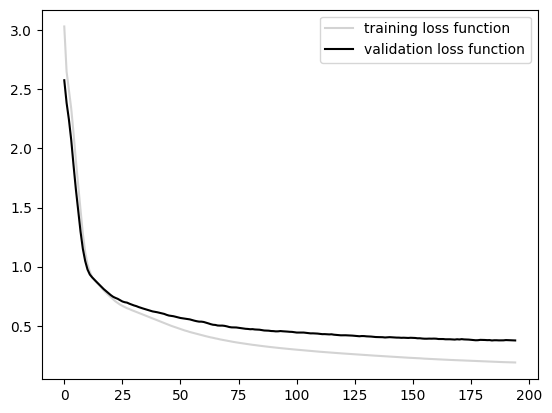

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step


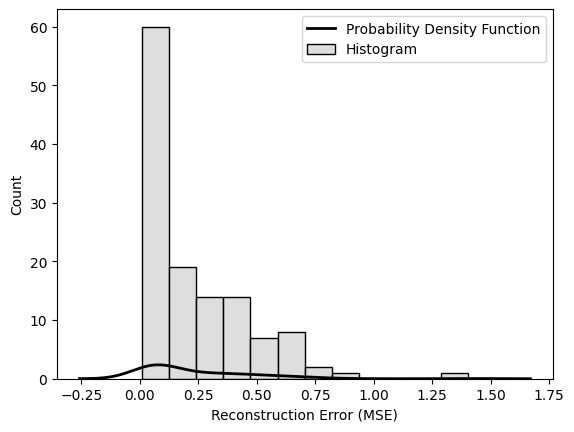

In [16]:
plt.plot(history_ae.history['loss'], label='training loss function', color = 'lightgrey')
plt.plot(history_ae.history['val_loss'], label='validation loss function', color = 'black')
plt.legend()
plt.show()


# reconstruction error 
reconstructed = autoencoder.predict(X_train_val)
reconstruction_error = np.mean(np.square(X_train_val - reconstructed), axis=0) #for each feature
# Plot histogram
sns.histplot(
    reconstruction_error,
    kde=False,
    color='lightgrey',
    label='Histogram'
)
# Plot KDE separately to set label
sns.kdeplot(
    reconstruction_error,
    color='black',
    linewidth=2,
    label='Probability Density Function',
)
plt.legend()
plt.xlabel('Reconstruction Error (MSE)')
plt.ylabel('Count')
plt.show()

In [17]:
reconstruction_error_df = pd.DataFrame(reconstruction_error, columns=['reconstruction_error'])
reconstruction_error_df.sort_values('reconstruction_error', ascending=False, inplace=True)
rec_err_std = reconstruction_error_df.std()
out_limit = float((reconstruction_error_df['reconstruction_error'].mean() + 3 * rec_err_std).iloc[0])
outliers = reconstruction_error_df[reconstruction_error_df['reconstruction_error'] > out_limit]
print(f"Number of outliers: {len(outliers)}, reconstruction MSE > {out_limit:.4f}")




Number of outliers: 1, reconstruction MSE > 0.9316


In [18]:
print(f"Mean Reconstruction Error: {np.mean(reconstruction_error)}")

Mean Reconstruction Error: 0.23174819412266784


In [19]:
pd.DataFrame(reconstructed)

,0,1,2,3,4,5,6,7,8,9,...,116,117,118,119,120,121,122,123,124,125
0,4.475634,8.403804,4.175460,3.523580,2.870743,0.786186,-0.287576,4.524301,0.673125,0.784331,...,-0.531078,-0.615680,-0.512935,-0.630698,-0.518619,-0.637558,-0.482827,-0.516230,-0.571677,-0.536456
1,2.892868,8.429049,0.822976,-0.133608,-0.145951,0.791481,3.969590,1.820669,-0.208337,-0.340508,...,-0.371118,-0.234264,-0.381363,-0.205286,-0.255942,-0.190111,-0.251434,-0.285839,-0.355397,-0.290448
2,5.861001,7.053561,5.675893,1.733559,3.031055,2.487604,3.800612,6.699585,0.264657,0.933240,...,-0.610083,-0.755514,-0.580030,-0.344411,-0.598188,-0.799241,-0.682631,-0.607151,-0.708109,-0.639467
3,3.991418,9.049889,3.915543,0.158395,0.292860,3.598054,-1.532117,4.259962,-0.402557,-0.116380,...,-0.253956,-0.353795,-0.196591,-0.699367,-0.279717,-0.616226,-0.398438,-0.398520,-0.289285,-0.330735
4,5.659243,8.430339,4.058553,4.493251,3.956769,0.744551,2.745821,4.152989,2.026971,1.507154,...,-0.796915,-0.684859,-0.714526,-1.003234,-0.817541,-0.571440,-0.682120,-0.667485,-0.862374,-0.795802
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
94,6.791744,6.344854,4.933167,0.134798,2.930557,4.188760,4.228889,5.573285,2.070101,1.384911,...,-1.100798,-0.851690,-1.164074,-0.976722,-0.850224,-0.232320,-0.638016,-0.752909,-0.656009,-0.647203
95,5.302829,6.517335,5.081372,1.286729,3.079956,5.762033,-0.544690,5.540541,2.121627,1.470475,...,-0.803701,-0.345551,-0.774520,-0.955001,-0.630071,-0.098100,-0.595711,-0.650445,-0.231264,-0.643707
96,6.226383,8.358746,3.890856,0.449605,0.029619,1.058213,2.667173,4.400889,0.205256,-0.762433,...,-0.440479,-0.392514,-0.285785,-0.148393,-0.568790,-0.609659,-0.376922,-0.361947,-0.240338,-0.527135
97,5.120077,8.423604,0.438983,-0.138320,-0.638699,-0.384493,0.707786,1.483400,0.402559,-0.335148,...,-0.411861,-0.451430,-0.427037,-1.001721,-0.402719,-0.351666,-0.539627,-0.448755,-0.318576,-0.377254


In [20]:
X_train_val

,d__Bacteria;p__Firmicutes;c__Bacilli;o__Erysipelotrichales;f__Erysipelotrichaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Aeromonadales;f__Aeromonadaceae,d__Bacteria;p__Firmicutes;c__Clostridia;o__Clostridiales;f__Clostridiaceae,d__Bacteria;p__Firmicutes;c__Bacilli;o__Lactobacillales;f__Enterococcaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Enterobacterales;f__Yersiniaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;__;__,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Enterobacterales;f__Enterobacteriaceae,d__Bacteria;p__Fusobacteriota;c__Fusobacteriia;o__Fusobacteriales;f__Fusobacteriaceae,d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Bacteroidales;f__Dysgonomonadaceae,d__Bacteria;p__Firmicutes;c__Bacilli;o__Erysipelotrichales;f__Erysipelatoclostridiaceae,...,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Alteromonadales;f__Alteromonadaceae,d__Bacteria;p__Acidobacteriota;c__Vicinamibacteria;o__Vicinamibacterales;f__uncultured,d__Bacteria;p__Verrucomicrobiota;c__Verrucomicrobiae;o__Pedosphaerales;f__Pedosphaeraceae,d__Bacteria;p__Firmicutes;c__Negativicutes;o__Veillonellales-Selenomonadales;f__Sporomusaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Burkholderiales;f__Alcaligenaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Vibrionales;f__Vibrionaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Pseudomonadales;f__Moraxellaceae,d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Flavobacteriales;f__Crocinitomicaceae,d__Bacteria;p__Campilobacterota;c__Campylobacteria;o__Campylobacterales;f__Arcobacteraceae,d__Bacteria;p__Actinobacteriota;c__Actinobacteria;o__Actinomycetales;f__Actinomycetaceae
12,4.900678,8.778924,3.956863,4.322797,3.545567,-0.497485,-0.497485,4.738957,1.294275,-0.497485,...,-0.497485,-0.497485,-0.497485,-0.497485,-0.497485,-0.497485,-0.497485,-0.497485,-0.497485,-0.497485
43,2.544049,8.984995,2.013421,-0.289164,-0.289164,1.097130,4.429334,0.809448,-0.289164,-0.289164,...,-0.289164,-0.289164,-0.289164,-0.289164,-0.289164,-0.289164,-0.289164,-0.289164,-0.289164,-0.289164
21,4.838797,7.851771,5.857916,-0.694592,2.077996,2.771144,4.218063,6.414470,-0.001445,1.703303,...,-0.694592,-0.694592,-0.694592,-0.694592,-0.694592,-0.694592,-0.694592,-0.694592,-0.694592,-0.694592
72,4.102492,9.439924,4.197803,-0.397317,-0.397317,2.000578,-0.397317,5.258674,-0.397317,-0.397317,...,-0.397317,-0.397317,-0.397317,-0.397317,-0.397317,-0.397317,-0.397317,-0.397317,-0.397317,-0.397317
13,6.000577,7.798981,3.773830,4.930640,4.030126,2.719181,3.177014,2.781701,2.376236,1.683089,...,-0.714807,-0.714807,-0.714807,-0.714807,-0.714807,-0.714807,-0.714807,-0.714807,-0.714807,-0.714807
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
109,6.503508,4.986240,4.725447,-0.775811,4.286784,7.197689,7.385849,5.595801,4.267614,1.526774,...,-0.775811,-0.775811,-0.775811,-0.775811,-0.775811,-0.775811,-0.775811,-0.775811,-0.775811,-0.775811
112,5.621300,7.804818,4.565022,2.798840,3.272624,4.229586,-0.697668,5.985693,3.659041,-0.697668,...,-0.697668,-0.697668,-0.697668,-0.697668,-0.697668,-0.697668,-0.697668,-0.697668,-0.697668,-0.697668
81,4.601858,8.374549,5.057184,-0.491892,-0.491892,-0.491892,3.034469,5.354547,1.117546,0.201255,...,-0.491892,-0.491892,-0.491892,-0.491892,-0.491892,-0.491892,-0.491892,-0.491892,-0.491892,-0.491892
116,5.009455,9.015051,0.308975,-0.384173,-0.384173,-0.384173,-0.384173,3.142188,-0.384173,-0.384173,...,-0.384173,-0.384173,-0.384173,-0.384173,-0.384173,-0.384173,-0.384173,-0.384173,-0.384173,-0.384173


# 5 classes


In [21]:
y_train_val = df_train_val['pond_5']
y_test = df_test['pond_5']

In [22]:
embeddings_df = pd.DataFrame(embeddings_train)
column_names = embeddings_df.columns.tolist()
column_names = [str(i) for i in column_names]
embeddings_df.columns = column_names
print(column_names)
y_train_val.reset_index(drop=True, inplace=True)
embeddings_df['pond'] = y_train_val
embeddings_df


['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', '15', '16', '17', '18']


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,pond
0,-5.471606,4.013606,-7.835044,2.759865,0.820279,2.264495,2.350480,-1.358736,-1.702683,7.395836,0.835196,1.261004,5.021589,-3.002620,-3.996279,1.904908,0.966701,-1.030140,0.874756,1
1,-1.987122,5.714920,-5.071189,1.411136,2.822909,-0.399554,2.217865,-1.487393,-0.906022,9.777203,0.822791,4.682437,2.489016,-3.421414,-0.990120,1.938153,0.855504,0.124755,-0.216414,0
2,-1.827488,1.632983,-8.328678,2.856300,-0.628629,4.726879,3.243319,-2.697469,-3.920405,7.379378,1.596054,-1.194083,6.616781,-5.958474,-0.867586,-2.222084,1.878041,-3.390052,2.286763,0
3,-5.507150,3.484038,-6.213568,5.520389,-1.197512,3.589011,2.957851,-2.509617,-2.277630,8.521100,0.915962,-0.310754,2.680414,-3.313724,-1.612265,-0.430756,-0.605859,-2.334292,1.729713,0
4,-4.319026,4.657712,-9.873729,2.161680,2.373801,2.708090,0.337189,-1.743400,-0.885996,8.855210,-0.985561,1.500390,6.917102,-5.170749,-3.910101,0.613098,3.923172,-0.869541,0.957945,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
94,0.648075,2.266971,-5.536351,1.424270,0.639323,5.673156,1.118221,0.297632,-4.226947,5.301238,-1.423557,-1.535205,5.886511,-6.409438,4.417804,-3.343724,2.942412,-4.091412,3.544117,4
95,-3.910313,2.456814,-5.416687,3.861403,-0.765474,7.439802,0.178946,-2.131168,-4.344272,5.328926,-0.848652,-6.032184,4.069179,-2.417481,0.582774,-2.718253,1.128068,-2.680900,4.124239,2
96,-1.701857,4.840727,-3.568703,0.873035,0.803518,1.601407,4.712895,-0.687395,-5.922299,7.854065,2.808147,2.702485,4.481851,-5.226130,0.880676,1.430714,0.863968,-1.885613,2.025143,1
97,-3.258697,5.351751,-0.919371,-0.716621,2.286993,0.362468,0.618101,-0.022434,-4.968112,8.815282,0.701974,3.150918,3.046688,-5.870165,1.182818,3.678232,-0.369914,0.292406,1.433738,0


In [23]:
#embeddings_df.to_csv('embeddings_5.csv', index=False)
#embeddings_df = pd.read_csv('embeddings_5.csv')

## Deep model

In [24]:
model5 = Sequential([
    Dense(128, input_shape=(encoding_dim,), activation='relu', kernel_regularizer=l2(0.01)),
    Dropout(rate=0.25),
    Dense(64, activation='relu', kernel_regularizer=l2(0.01)),
    Dense(8, activation='relu', kernel_regularizer=l2(0.01)),
    Dense(5, activation='softmax')

])
model5.summary()
model5.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])


C:\Users\marek\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\keras\src\layers\core\dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_14 (Dense)                │ (None, 128)            │         2,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 8)              │           520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 5)              │            45 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,381 (44.46 KB)

 Trainable params: 11,381 (44.46 KB)

 Non-trainable params: 0 (0.00 B)

### Crossvalidation

Number of classes: 5
training for 1 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 396ms/step - accuracy: 0.4000 - loss: 2.2577
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 183ms/step
predicted classes:       [3 2 4 1 2 4 0 1 3 3 1 2 4 4 4 4 4 1 4 4]
true validation classes: [3 3 1 2 2 0 1 1 3 1 1 4 2 4 0 2 4 1 3 2]
mean confidence score: 75.2712, sd confidence score: 171.5915
training for 2 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.5000 - loss: 1.8703
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
predicted classes:       [4 4 1 2 4 1 4 2 3 4 1 3 1 4 4 2 3 0 2 0]
true validation classes: [0 0 0 2 4 0 0 2 3 0 1 3 4 4 0 2 3 1 2 1]
mean confidence score: 264.5689, sd confidence score: 436.8141
training for 3 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.4000 - loss: 2.3771
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
predicted classes:       [1 4 3 2 4 1 4 3 1 4 1 3 4 0 2 3 3 4 4 3]
true validation classes: [1 1 2 2 0 4 0 3 0 4 3 1 4 2 2 1 3 1 4 1]
mean confidence score: 153.4809, sd confidence score: 

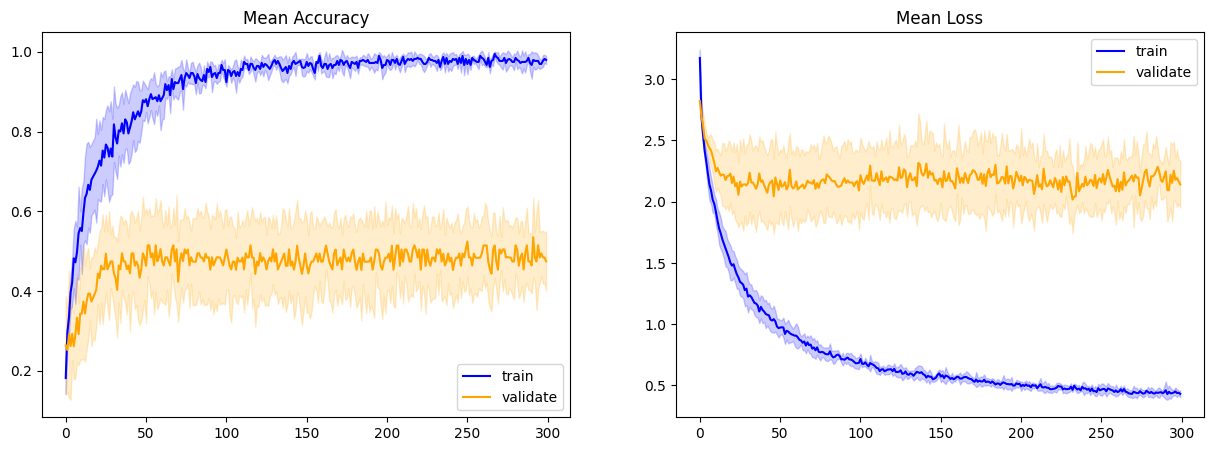

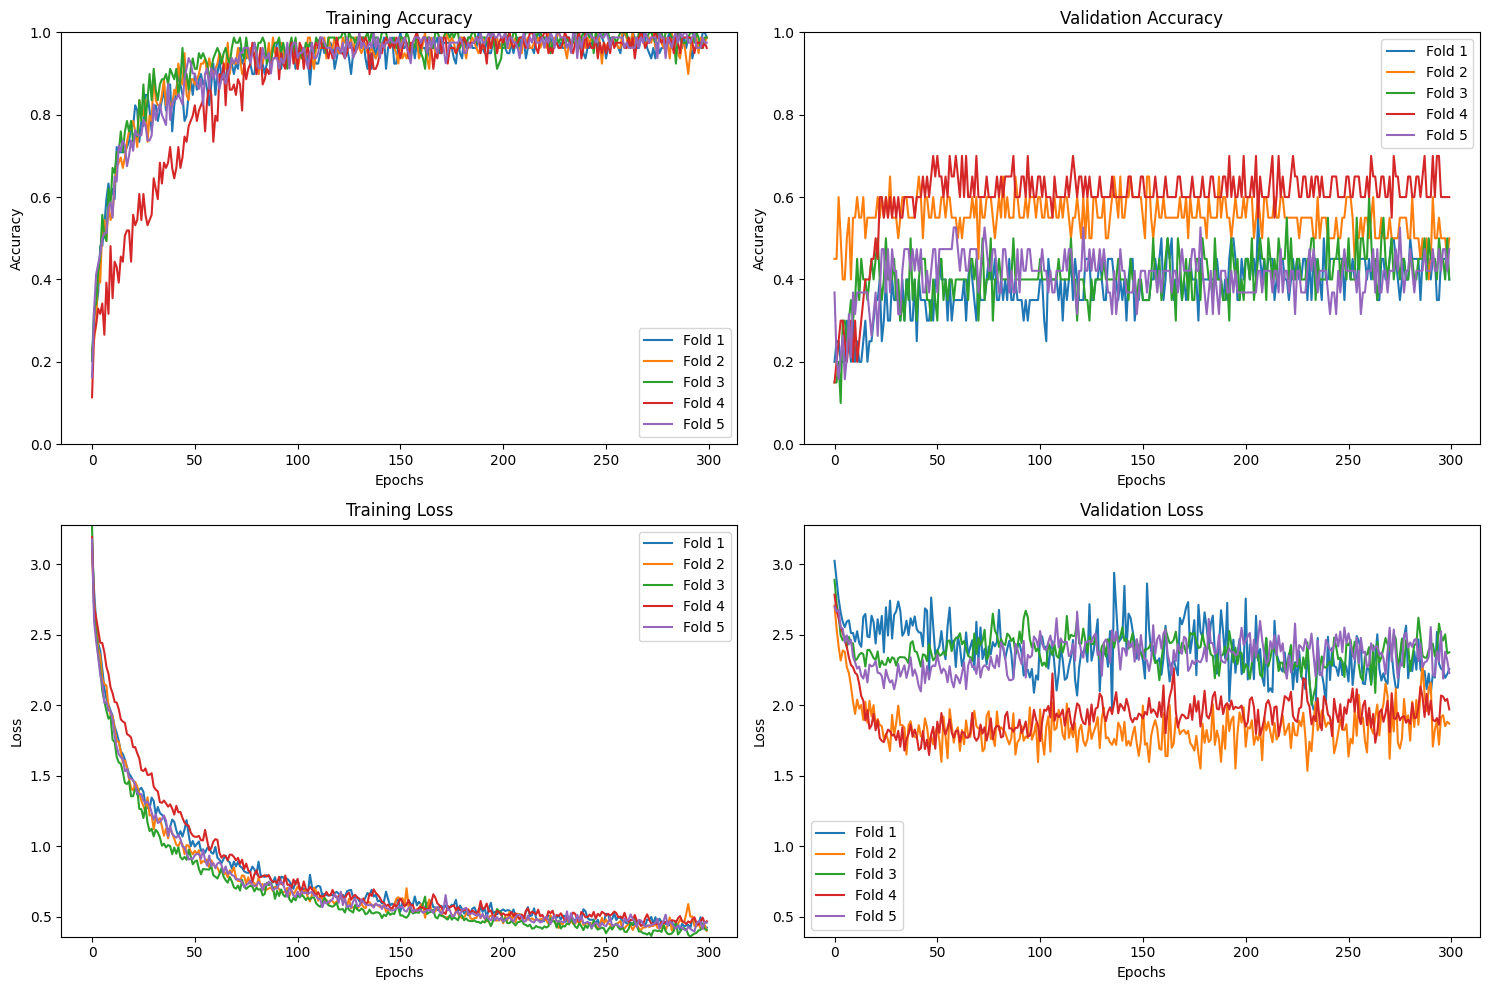

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
predicted classes:       [1 0 1 2 0 3 3 1 4 4 0 2 4 1 3 0 1 0 3]
true validation classes: [4 0 4 2 2 0 3 1 2 0 2 4 4 3 3 4 1 0 3]


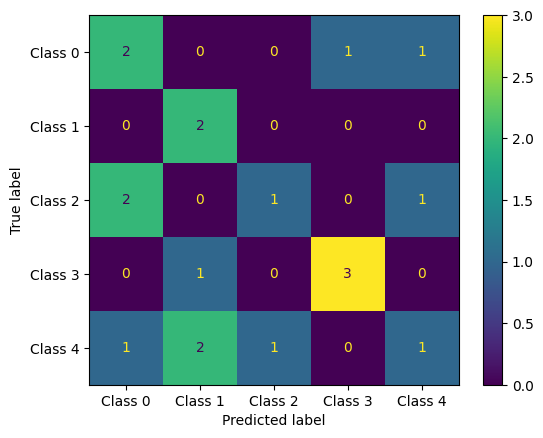

In [25]:
mean_acc_DNN_5_val, sd_acc_DNN_5_val = crossvalidate(embeddings_df, model5, column_names, 'pond', kf, 300)

### Testing 

In [26]:
X_train = embeddings_df[column_names]
y_train = embeddings_df['pond']
y_train = keras.utils.to_categorical(y_train)
X_test = pd.DataFrame(embeddings_test, columns=column_names)
y_test = df_test['pond_5']
y_test = keras.utils.to_categorical(y_test)

Epoch 1/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8534 - loss: 0.8115 - val_accuracy: 0.5600 - val_loss: 1.5051
Epoch 2/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8419 - loss: 0.7971 - val_accuracy: 0.6400 - val_loss: 1.3124
Epoch 3/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8284 - loss: 0.7651 - val_accuracy: 0.6400 - val_loss: 1.4701
Epoch 4/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7849 - loss: 0.7528 - val_accuracy: 0.6400 - val_loss: 1.2571
Epoch 5/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8670 - loss: 0.6816 - val_accuracy: 0.6400 - val_loss: 1.6244
Epoch 6/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8205 - loss: 0.8374 - val_accuracy: 0.6800 - val_loss: 1.0981
Epoch 7/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9399 - loss: 0.6006 - val_accuracy: 0.6000 - val_loss: 1.3392
Epoch 8/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9607 - loss: 0.5324 - val_accuracy: 0.6000 - v

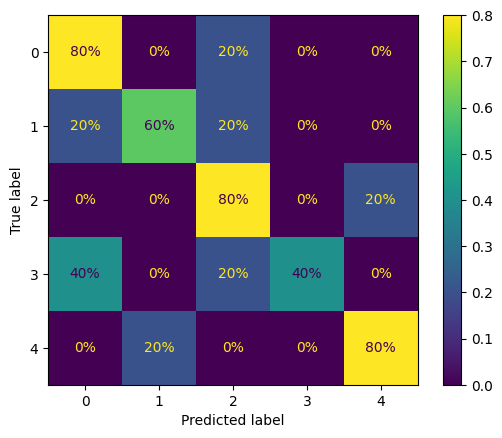

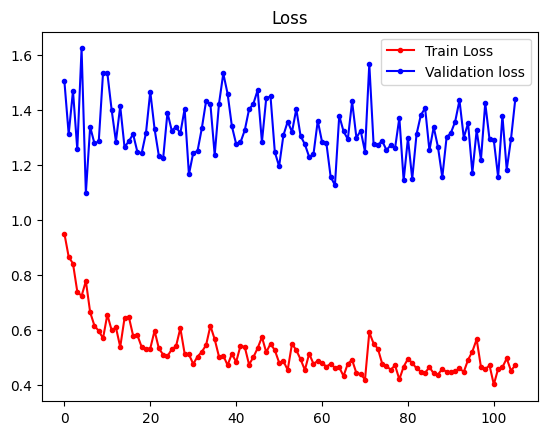

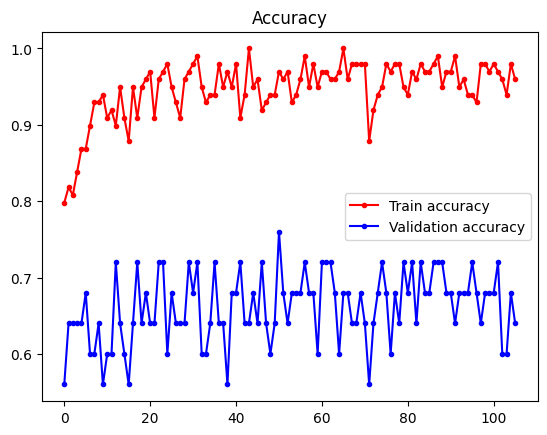

In [27]:
history5=model5.fit(X_train, y_train, epochs = 500, verbose = 1, shuffle = True, batch_size = 3, validation_data = (X_test, y_test), callbacks = [EarlyStopping(monitor='val_loss', patience=100, restore_best_weights=True)])
acc_DNN_5_test = evaluate_model(model5, history5, X_test, y_test)
    

## Shallow model

In [28]:
model5_s = Sequential([
    Dense(19, input_shape=(encoding_dim,), activation='relu', kernel_regularizer=l2(0.01)),
    Dropout(rate=0.25),
    Dense(5, activation='softmax')
])
model5_s.summary()
model5_s.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

C:\Users\marek\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\keras\src\layers\core\dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_18 (Dense)                │ (None, 19)             │           380 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 19)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 5)              │           100 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 480 (1.88 KB)

 Trainable params: 480 (1.88 KB)

 Non-trainable params: 0 (0.00 B)

Number of classes: 5
training for 1 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 356ms/step - accuracy: 0.3000 - loss: 1.6889
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 112ms/step
predicted classes:       [3 3 4 1 2 4 0 2 4 3 1 0 4 0 1 4 4 1 4 4]
true validation classes: [3 3 1 2 2 0 1 1 3 1 1 4 2 4 0 2 4 1 3 2]
mean confidence score: 8.392, sd confidence score: 9.8151
training for 2 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step - accuracy: 0.5500 - loss: 1.1023
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
predicted classes:       [4 4 1 4 4 1 0 2 3 3 0 3 4 4 4 2 3 1 2 0]
true validation classes: [0 0 0 2 4 0 0 2 3 0 1 3 4 4 0 2 3 1 2 1]
mean confidence score: 23.3378, sd confidence score: 39.291
training for 3 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - accuracy: 0.3500 - loss: 1.8919
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
predicted classes:       [1 3 3 2 4 4 0 0 1 4 1 3 2 3 2 3 2 3 4 3]
true validation classes: [1 1 2 2 0 4 0 3 0 4 3 1 4 2 2 1 3 1 4 1]
mean confidence score: 49.1164, sd confidence score: 105.5846

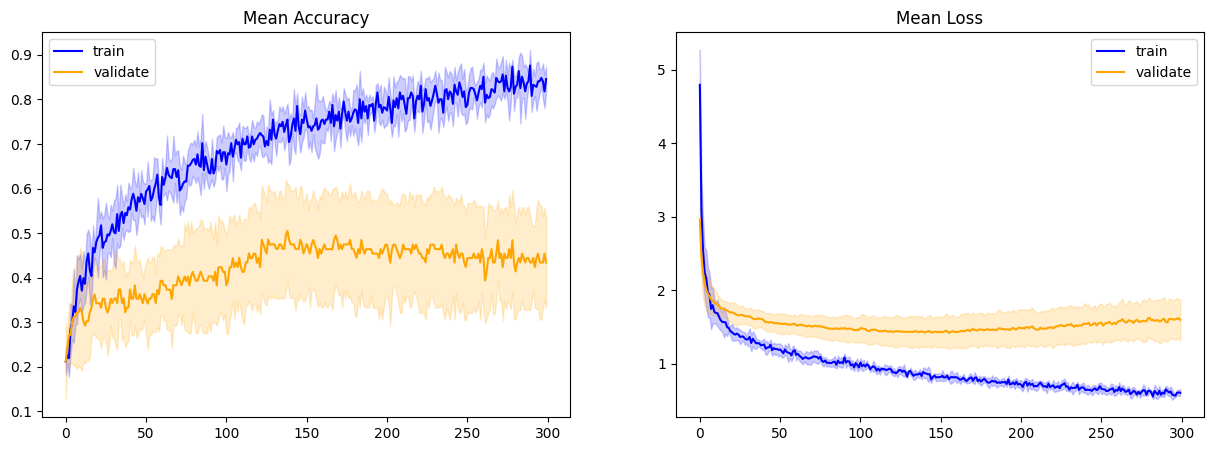

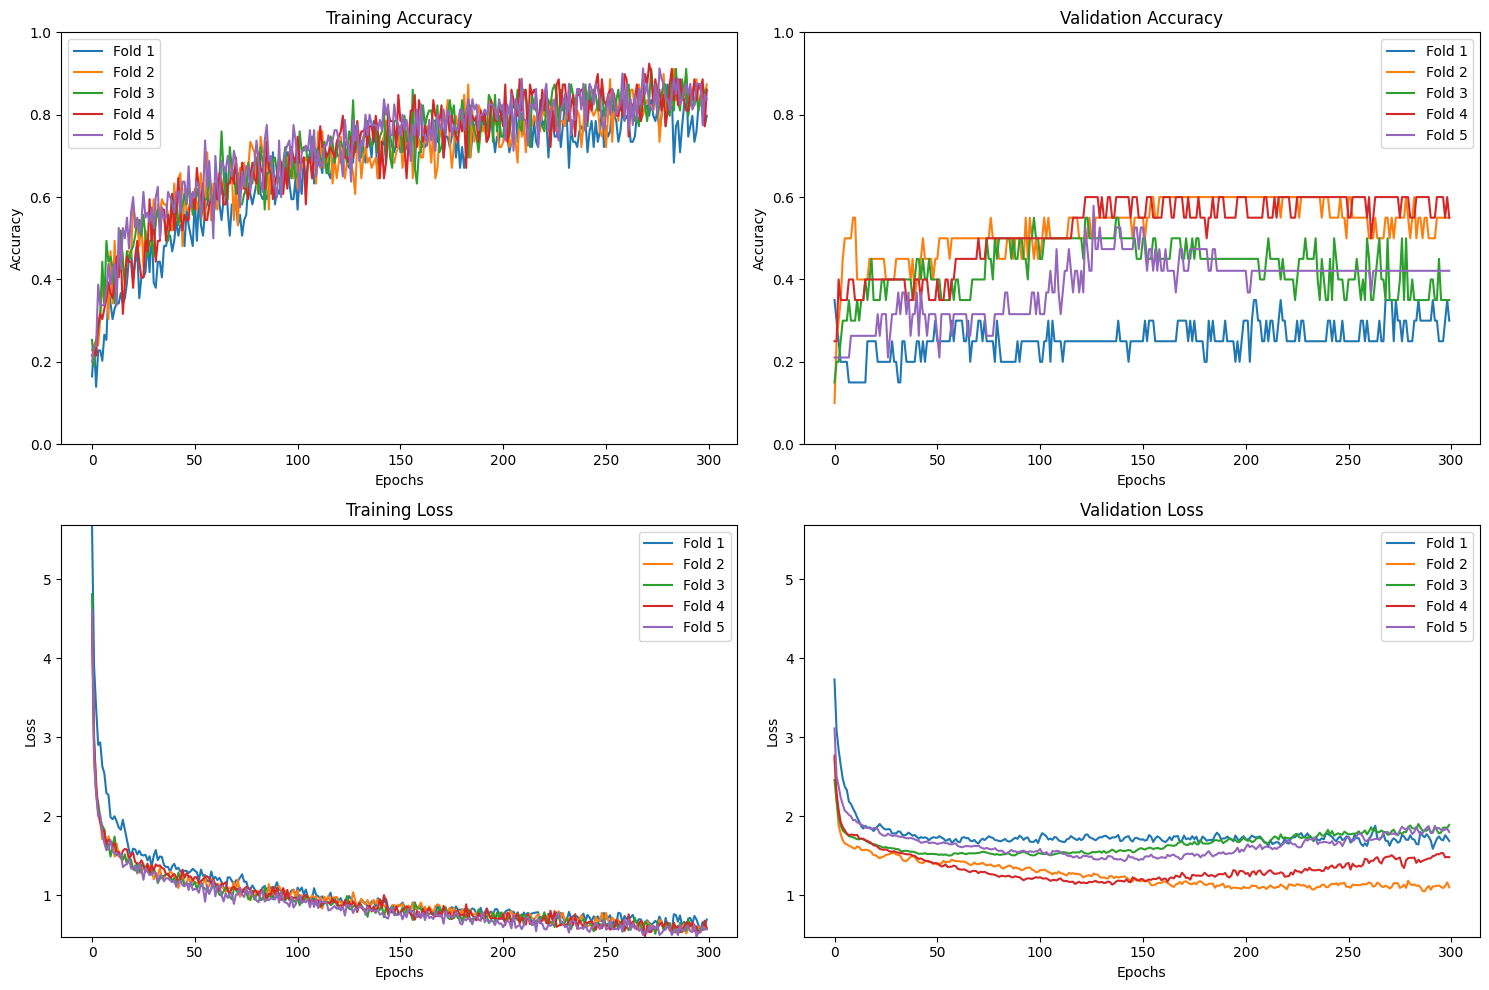

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
predicted classes:       [1 4 1 2 4 3 3 1 2 4 0 2 3 1 3 0 1 0 3]
true validation classes: [4 0 4 2 2 0 3 1 2 0 2 4 4 3 3 4 1 0 3]


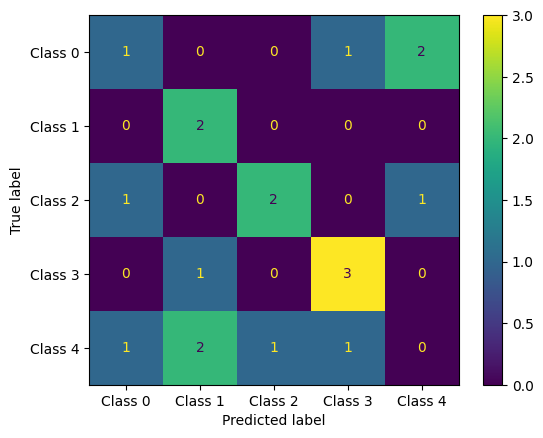

In [29]:
mean_acc_SNN_5_val, sd_acc_SNN_5_val = crossvalidate(embeddings_df, model5_s, column_names, 'pond', kf, 300)

### Test

Epoch 1/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7138 - loss: 0.8366 - val_accuracy: 0.5200 - val_loss: 1.2920
Epoch 2/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6559 - loss: 1.0910 - val_accuracy: 0.5600 - val_loss: 1.2615
Epoch 3/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7861 - loss: 0.8047 - val_accuracy: 0.5600 - val_loss: 1.2392
Epoch 4/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7815 - loss: 0.7417 - val_accuracy: 0.5200 - val_loss: 1.2551
Epoch 5/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7414 - loss: 0.7682 - val_accuracy: 0.5200 - val_loss: 1.2388
Epoch 6/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7280 - loss: 0.8785 - val_accuracy: 0.5600 - val_loss: 1.2644
Epoch 7/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7446 - loss: 0.7830 - val_accuracy: 0.5600 - val_loss: 1.2338
Epoch 8/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6395 - loss: 0.7771 - val_accuracy: 0.5200 - 

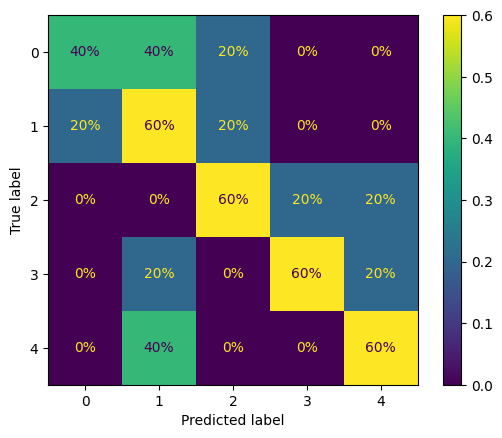

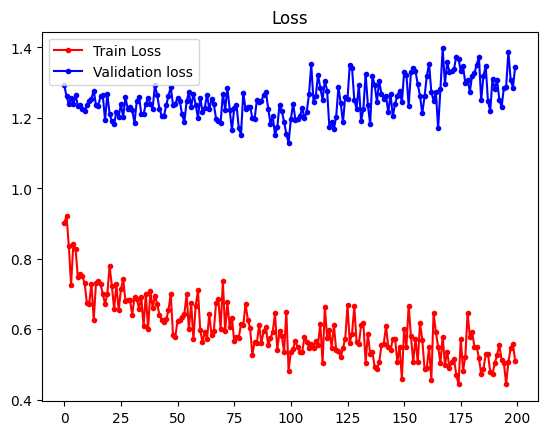

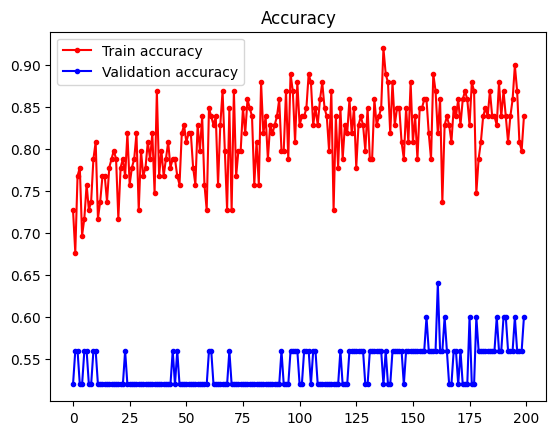

In [30]:
history5_s=model5_s.fit(X_train, y_train, epochs = 500, verbose = 1, shuffle = True, batch_size = 3, validation_data = (X_test, y_test), callbacks = [EarlyStopping(monitor='val_loss', patience=100, restore_best_weights=True)])
acc_SNN_5_test = evaluate_model(model5_s, history5_s, X_test, y_test)

## XGBoost

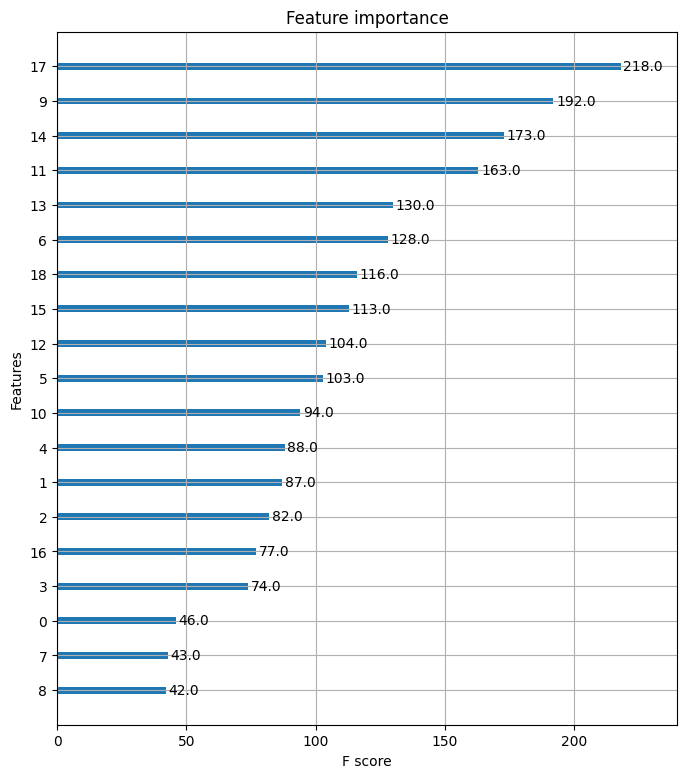

Accuracy0.4
true: [3 0 2 1 3 1 0 1 2 2 4 3 4 0 4 1 3 0 2 4 0 1 4 3 2]
predicted: [3. 4. 2. 1. 0. 4. 0. 0. 3. 1. 0. 3. 2. 0. 4. 4. 0. 1. 0. 4. 4. 4. 1. 3.
 2.]


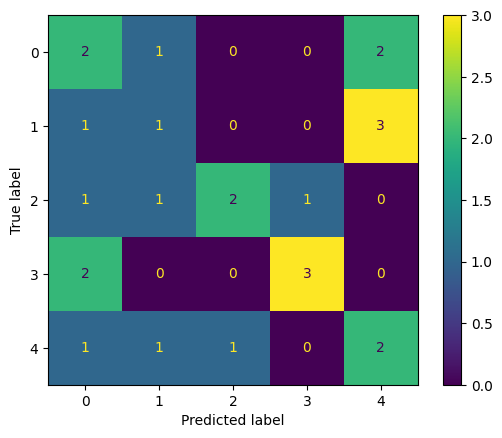

In [31]:
target = "pond_5"
dtrain = xgb.DMatrix(X_train, label=df_train_val[target].values, feature_names=column_names)  
dtest = xgb.DMatrix(X_test, label=df_test[target].values, feature_names=column_names)
params = {
    'objective': 'multi:softmax',
    'num_class': 5,
    'max_depth': 3, # maximum deepth of the tree, used to controll complexity of the model
    'eta': 0.1,
    'seed': 111
}

x2 = xgb.train(params, dtrain, num_boost_round=100)

xgb_pred = x2.predict(dtest)
xgb_acc = accuracy_score(df_test[target].values, xgb_pred)
acc_XGB_5_test = xgb_acc

fig, ax = plt.subplots(figsize=(8, 9))
xgb.plot_importance(x2, ax=ax)
plt.show()

print(f"Accuracy{xgb_acc}")
print(f"true: {df_test[target].values}")
print(f"predicted: {xgb_pred}")

cm = confusion_matrix(df_test[target].values, xgb_pred)
ConfusionMatrixDisplay(cm).plot()

# 3 Classes

In [32]:
y = df_train_val['pond_3']
y.reset_index(drop=True, inplace=True)
embeddings_df['pond'] = y


## Dense model

In [33]:
model3 = Sequential([
    Dense(128, input_shape=(encoding_dim,), activation='relu', kernel_regularizer=l2(0.01)),
    Dropout(rate=0.25),
    Dense(64, activation='relu', kernel_regularizer=l2(0.01)),
    Dense(8, activation='relu', kernel_regularizer=l2(0.01)),
    Dense(3, activation='softmax')

])
model3.summary()
model3.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])


C:\Users\marek\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\keras\src\layers\core\dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_20 (Dense)                │ (None, 128)            │         2,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 8)              │           520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,363 (44.39 KB)

 Trainable params: 11,363 (44.39 KB)

 Non-trainable params: 0 (0.00 B)

### Crossvalidation

Number of classes: 3
training for 1 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 430ms/step - accuracy: 0.6500 - loss: 1.4036
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 127ms/step
predicted classes:       [1 2 2 2 2 2 0 1 1 1 1 2 2 2 2 1 2 1 2 2]
true validation classes: [1 1 1 2 2 0 1 1 1 1 1 2 2 2 0 2 2 1 1 2]
mean confidence score: 149.8413, sd confidence score: 265.2257
training for 2 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 0.7000 - loss: 1.2207
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step
predicted classes:       [2 2 0 2 2 1 0 2 1 2 1 1 2 2 2 2 1 1 2 0]
true validation classes: [0 0 0 2 2 0 0 2 1 0 1 1 2 2 0 2 1 1 2 1]
mean confidence score: 287.9963, sd confidence score: 864.3305
training for 3 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - accuracy: 0.6500 - loss: 1.3895
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step
predicted classes:       [1 1 1 2 0 1 2 1 1 2 1 1 2 0 2 1 2 2 2 1]
true validation classes: [1 1 2 2 0 2 0 1 0 2 1 1 2 2 2 1 1 1 2 1]
mean confidence score: 8063685.085, sd confidence sco

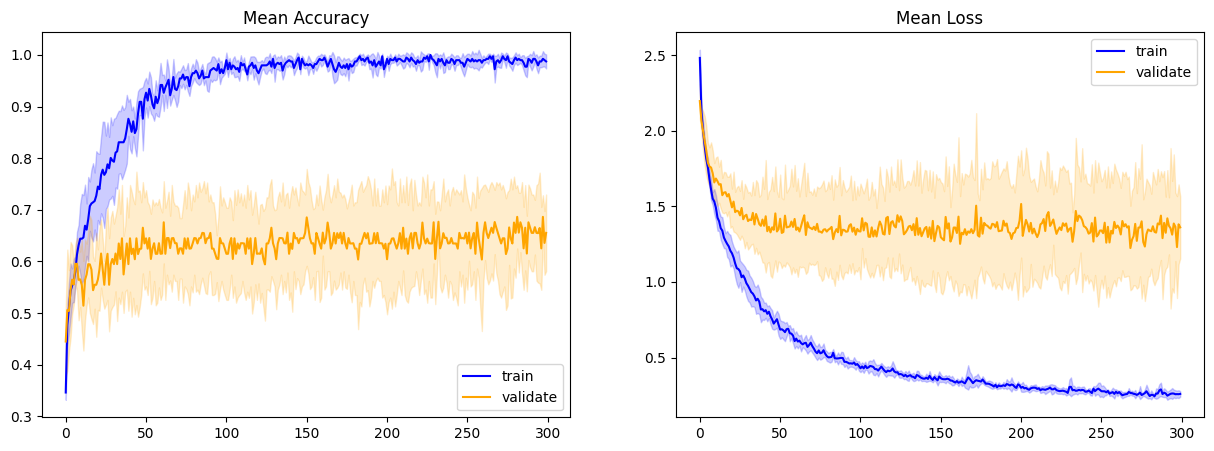

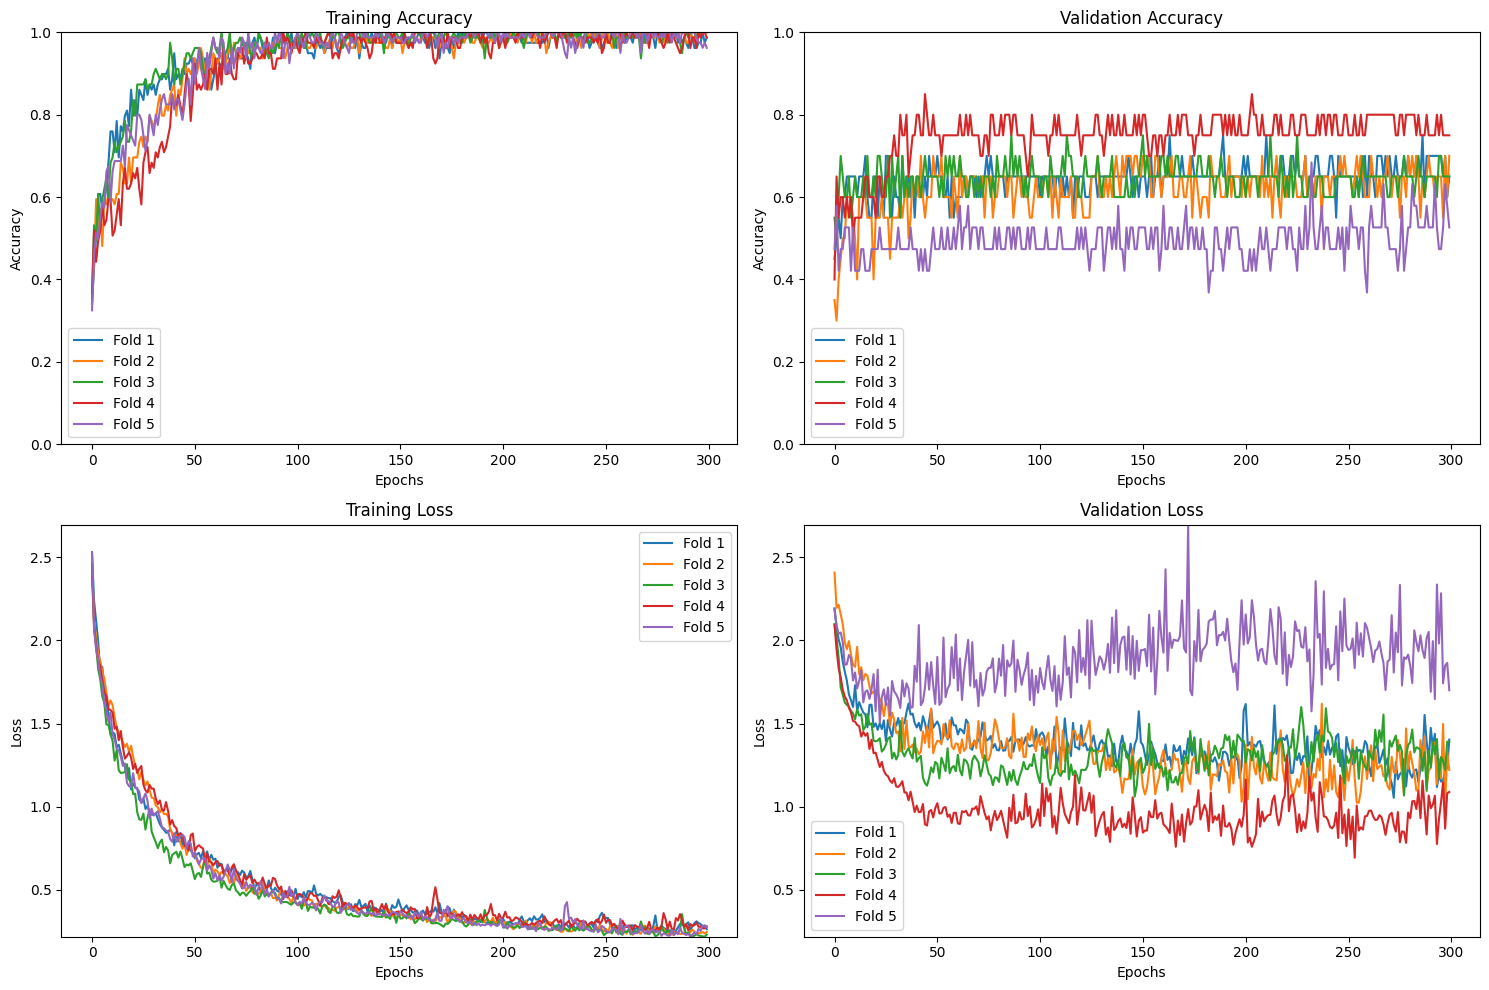

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
predicted classes:       [0 2 2 2 0 1 1 1 2 2 0 2 1 1 1 0 2 0 1]
true validation classes: [2 0 2 2 2 0 1 1 2 0 2 2 2 1 1 2 1 0 1]


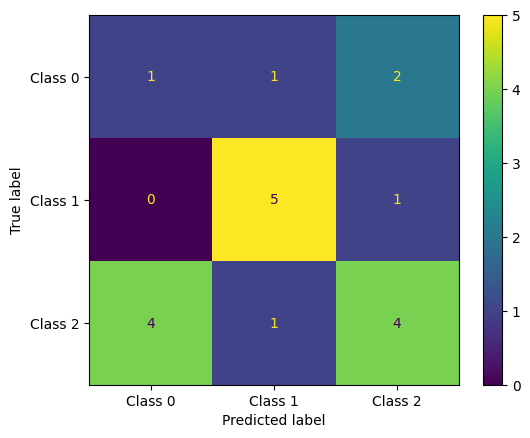

In [34]:
mean_acc_DNN_3_val, sd_acc_DNN_3_val = crossvalidate(embeddings_df, model3, column_names, 'pond',kf,300)

### Test

In [35]:
X_train = embeddings_df[column_names]
y_train = embeddings_df['pond']
y_train = keras.utils.to_categorical(y_train)
X_test = pd.DataFrame(embeddings_test, columns=column_names)
y_test = df_test['pond_3']
y_test = keras.utils.to_categorical(y_test)

Epoch 1/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.3886 - loss: 2.4670 - val_accuracy: 0.5600 - val_loss: 2.0214
Epoch 2/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.4577 - loss: 2.0409 - val_accuracy: 0.6400 - val_loss: 1.8646
Epoch 3/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.4934 - loss: 1.8086 - val_accuracy: 0.5600 - val_loss: 1.7766
Epoch 4/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5555 - loss: 1.6626 - val_accuracy: 0.6000 - val_loss: 1.6475
Epoch 5/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6584 - loss: 1.5953 - val_accuracy: 0.5600 - val_loss: 1.6449
Epoch 6/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6150 - loss: 1.5952 - val_accuracy: 0.6000 - val_loss: 1.4962
Epoch 7/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6021 - loss: 1.5000 - val_accuracy: 0.5600 - val_loss: 1.4570
Epoch 8/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6920 - loss: 1.3626 - val_accuracy: 0.6000 - 

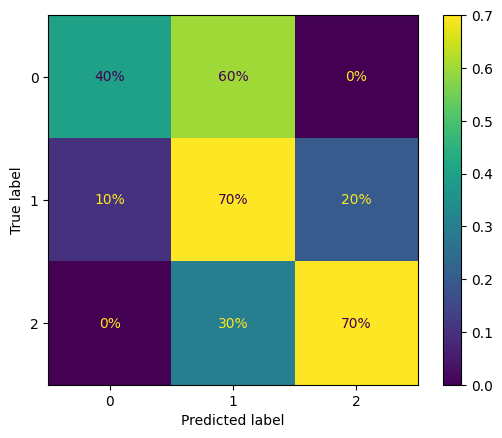

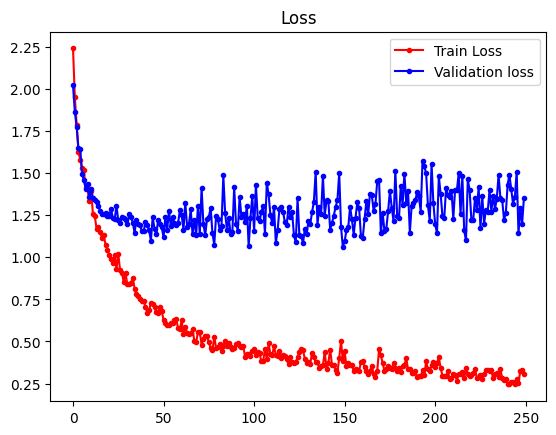

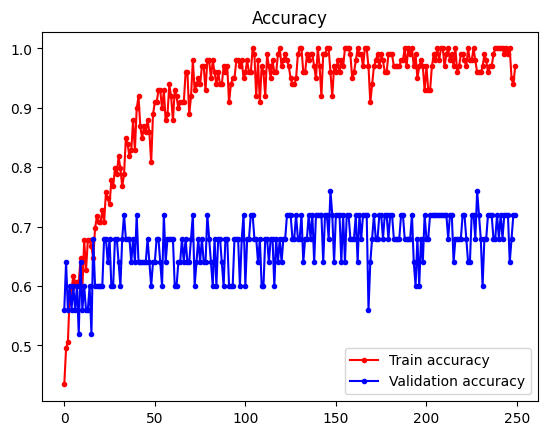

In [36]:
reset_weights(model3)
history3 = model3.fit(X_train, y_train, epochs = 500, verbose = 1, 
                      shuffle = True, batch_size = 3, validation_data = (X_test, y_test),
                      callbacks = [EarlyStopping(monitor='val_loss', patience=100, 
                                                   restore_best_weights=True)])
acc_DNN_3_test = evaluate_model(model3, history3, X_test, y_test)

## Shallow model    

In [37]:
model3_s = Sequential([
    Dense(19, input_shape=(encoding_dim,), activation='relu', kernel_regularizer=l2(0.01)),
    Dropout(rate=0.25),
    Dense(3, activation='softmax')
])
model3_s.summary()
model3_s.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

C:\Users\marek\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\keras\src\layers\core\dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_24 (Dense)                │ (None, 19)             │           380 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 19)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_25 (Dense)                │ (None, 3)              │            60 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 440 (1.72 KB)

 Trainable params: 440 (1.72 KB)

 Non-trainable params: 0 (0.00 B)

### Crossvalidation

Number of classes: 3
training for 1 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 347ms/step - accuracy: 0.6500 - loss: 0.9756
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 129ms/step
predicted classes:       [1 1 2 2 2 1 2 2 1 1 1 2 2 2 1 1 2 1 2 2]
true validation classes: [1 1 1 2 2 0 1 1 1 1 1 2 2 2 0 2 2 1 1 2]
mean confidence score: 46.4342, sd confidence score: 150.5385
training for 2 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step - accuracy: 0.6000 - loss: 1.0843
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
predicted classes:       [2 2 2 2 2 1 2 2 1 2 1 1 2 2 2 2 1 1 2 0]
true validation classes: [0 0 0 2 2 0 0 2 1 0 1 1 2 2 0 2 1 1 2 1]
mean confidence score: 43.5316, sd confidence score: 96.4882
training for 3 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step - accuracy: 0.5500 - loss: 1.1253
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step
predicted classes:       [2 1 1 2 2 1 2 1 1 2 1 1 2 1 2 1 2 2 2 1]
true validation classes: [1 1 2 2 0 2 0 1 0 2 1 1 2 2 2 1 1 1 2 1]
mean confidence score: 1779443343.1769, sd confidence sc

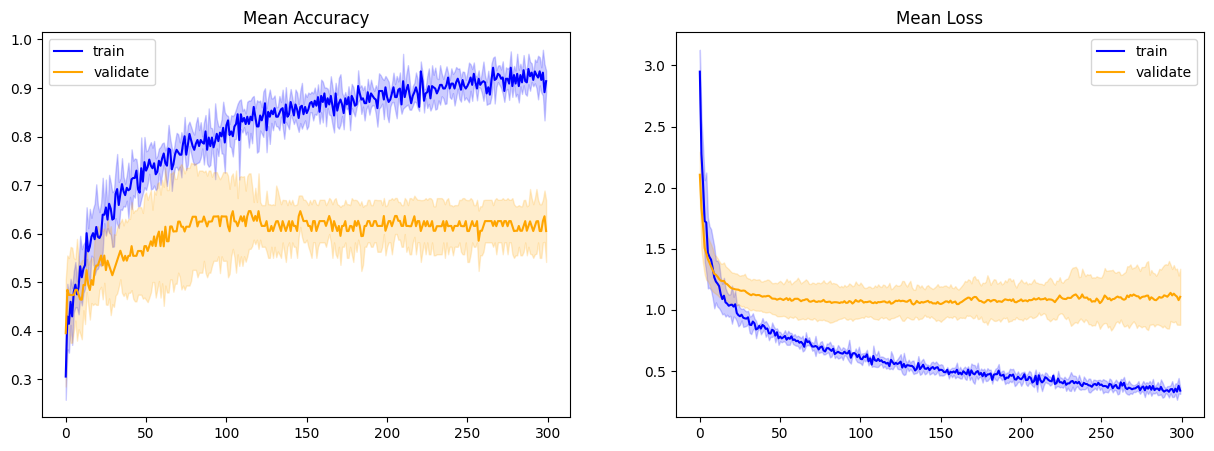

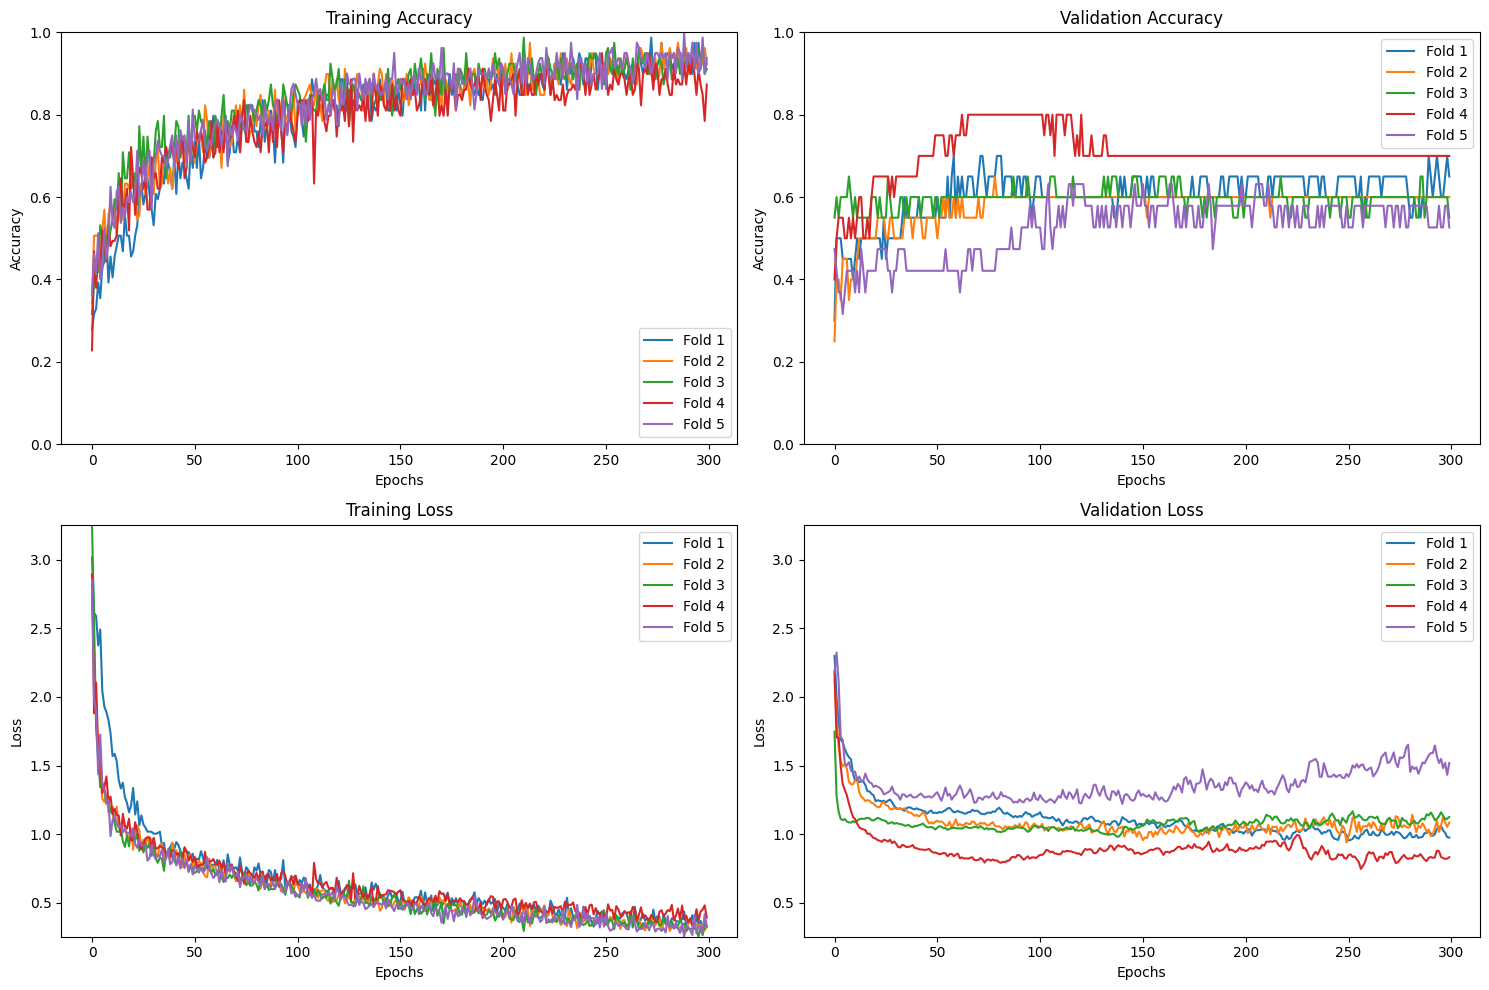

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step
predicted classes:       [0 2 1 2 0 1 1 1 2 2 0 2 1 1 1 0 1 0 1]
true validation classes: [2 0 2 2 2 0 1 1 2 0 2 2 2 1 1 2 1 0 1]


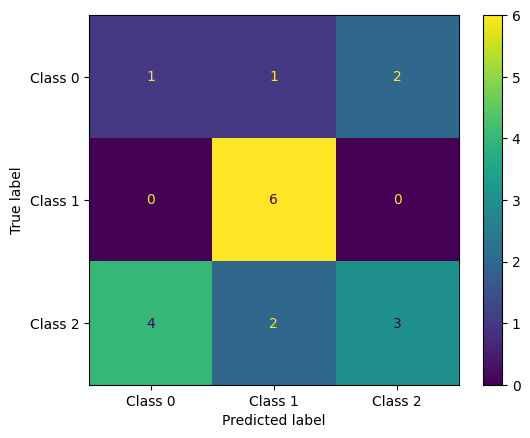

In [38]:
mean_acc_SNN_3_val, sd_acc_SNN_3_val = crossvalidate(embeddings_df, model3_s, column_names, 'pond',kf,300,True)

### test

In [39]:
model3_s.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

Epoch 1/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 0.8870 - loss: 0.5067 - val_accuracy: 0.6400 - val_loss: 0.8313
Epoch 2/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8993 - loss: 0.4909 - val_accuracy: 0.6400 - val_loss: 0.8132
Epoch 3/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8363 - loss: 0.5216 - val_accuracy: 0.6400 - val_loss: 0.7628
Epoch 4/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8999 - loss: 0.4928 - val_accuracy: 0.6400 - val_loss: 0.7893
Epoch 5/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9166 - loss: 0.4253 - val_accuracy: 0.6400 - val_loss: 0.7484
Epoch 6/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8916 - loss: 0.5274 - val_accuracy: 0.6800 - val_loss: 0.7084
Epoch 7/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9256 - loss: 0.3409 - val_accuracy: 0.6400 - val_loss: 0.7453
Epoch 8/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8160 - loss: 0.4491 - val_accuracy: 0.6800 - 

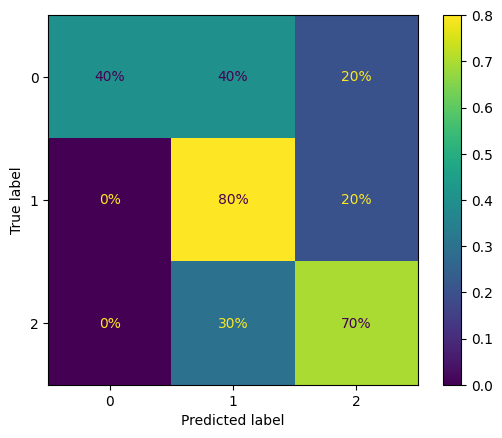

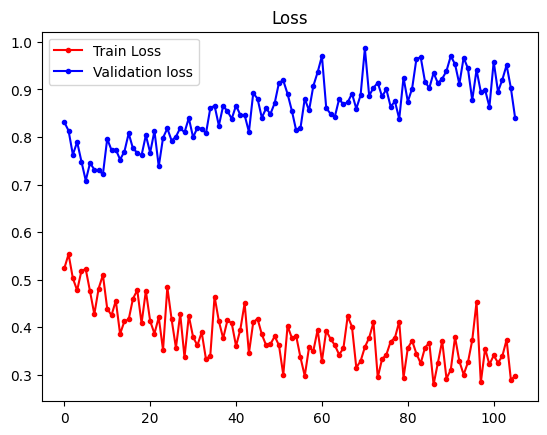

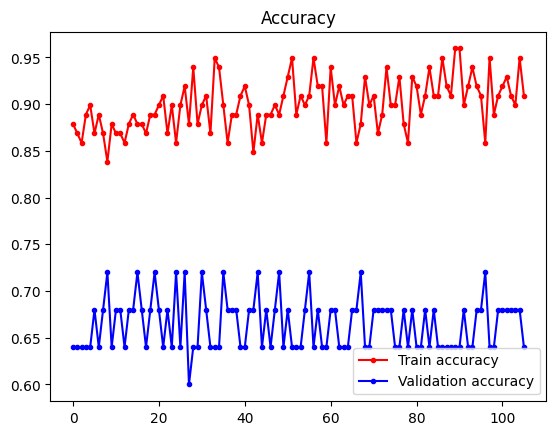

In [40]:
history3_s=model3_s.fit(X_train, y_train, epochs = 500, verbose = 1, 
                        shuffle = True, batch_size = 3, validation_data = (X_test, y_test), 
                        callbacks = [EarlyStopping(monitor='val_loss', patience=100, 
                                                   restore_best_weights=True)])
acc_SNN_3_test = evaluate_model(model3_s, history3_s, X_test, y_test)

## XGBoost

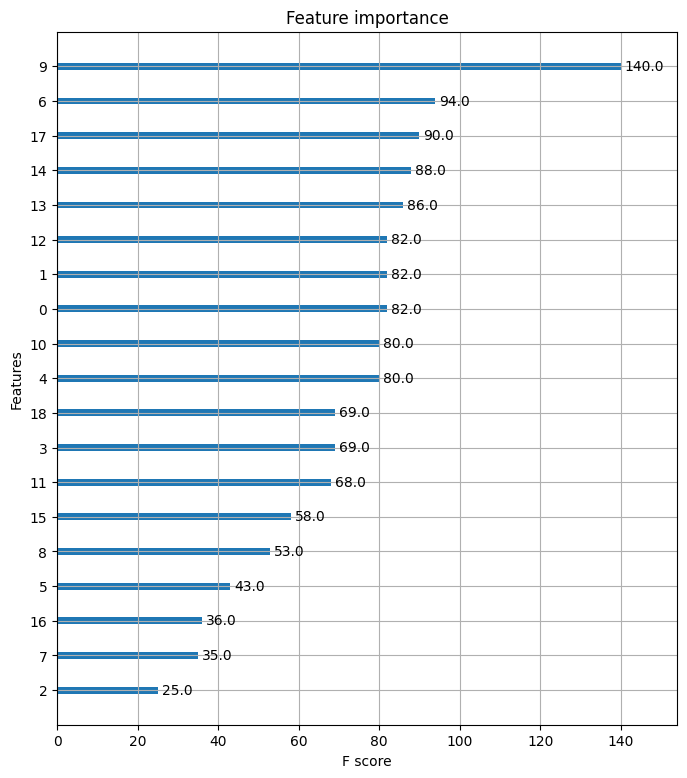

Accuracy0.52
true: [1 0 2 1 1 1 0 1 2 2 2 1 2 0 2 1 1 0 2 2 0 1 2 1 2]
predicted: [1. 2. 2. 1. 0. 2. 2. 1. 1. 1. 2. 2. 2. 1. 2. 1. 1. 1. 2. 2. 2. 2. 1. 1.
 2.]


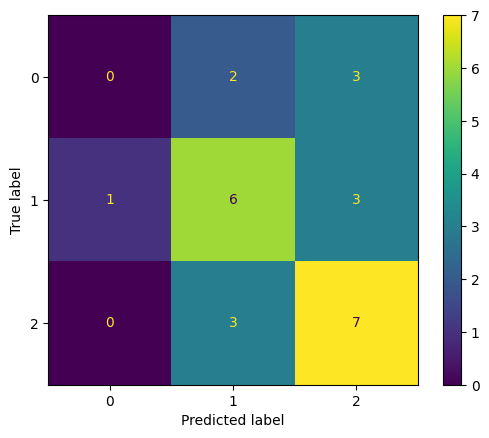

In [41]:
target = "pond_3"
dtrain = xgb.DMatrix(X_train, label=df_train_val[target].values, feature_names=column_names)  
dtest = xgb.DMatrix(X_test, label=df_test[target].values, feature_names=column_names)
params = {
    'objective': 'multi:softmax',
    'num_class': 5,
    'max_depth': 3, 
    'eta': 0.1,
    'seed': 111
}

x2 = xgb.train(params, dtrain, num_boost_round=100)

xgb_pred = x2.predict(dtest)
xgb_acc = accuracy_score(df_test[target].values, xgb_pred)
acc_XGB_3_test = xgb_acc
fig, ax = plt.subplots(figsize=(8, 9))
xgb.plot_importance(x2, ax=ax)
plt.show()

print(f"Accuracy{xgb_acc}")
print(f"true: {df_test[target].values}")
print(f"predicted: {xgb_pred}")

cm = confusion_matrix(df_test[target].values, xgb_pred)
ConfusionMatrixDisplay(cm).plot()

# 2 Classes

## Deep model

In [42]:
y = df_train_val['pond_2']
y.reset_index(drop=True, inplace=True)
embeddings_df['pond'] = y

In [43]:
model2 = Sequential([
    Dense(128, input_shape=(encoding_dim,), activation='relu', kernel_regularizer=l2(0.01)),
    Dropout(rate=0.25),
    Dense(64, activation='relu', kernel_regularizer=l2(0.01)),
    Dense(8, activation='relu', kernel_regularizer=l2(0.01)),
    Dense(2, activation='softmax')

])
model2.summary()
model2.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

C:\Users\marek\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\keras\src\layers\core\dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_26 (Dense)                │ (None, 128)            │         2,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_27 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_28 (Dense)                │ (None, 8)              │           520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_29 (Dense)                │ (None, 2)              │            18 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,354 (44.35 KB)

 Trainable params: 11,354 (44.35 KB)

 Non-trainable params: 0 (0.00 B)

### Crossvalidation

Number of classes: 2
training for 1 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 436ms/step - accuracy: 0.7500 - loss: 1.2201
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 146ms/step
predicted classes:       [0 0 1 0 1 0 0 0 0 0 0 1 1 1 1 0 1 0 1 1]
true validation classes: [0 0 0 1 1 0 0 0 0 0 0 1 1 1 0 1 1 0 0 1]
mean confidence score: 5437.8048, sd confidence score: 10850.8124
training for 2 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.7000 - loss: 1.1851
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
predicted classes:       [1 1 0 1 1 0 1 1 0 1 0 0 0 1 1 1 0 0 1 0]
true validation classes: [0 0 0 1 1 0 0 1 0 0 0 0 1 1 0 1 0 0 1 0]
mean confidence score: 295.9549, sd confidence score: 533.5261
training for 3 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 0.7000 - loss: 0.8612
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step
predicted classes:       [0 0 0 1 1 0 1 0 0 1 0 0 1 1 1 0 1 1 1 0]
true validation classes: [0 0 1 1 0 1 0 0 0 1 0 0 1 1 1 0 0 0 1 0]
mean confidence score: 459279.3949, sd confidence 

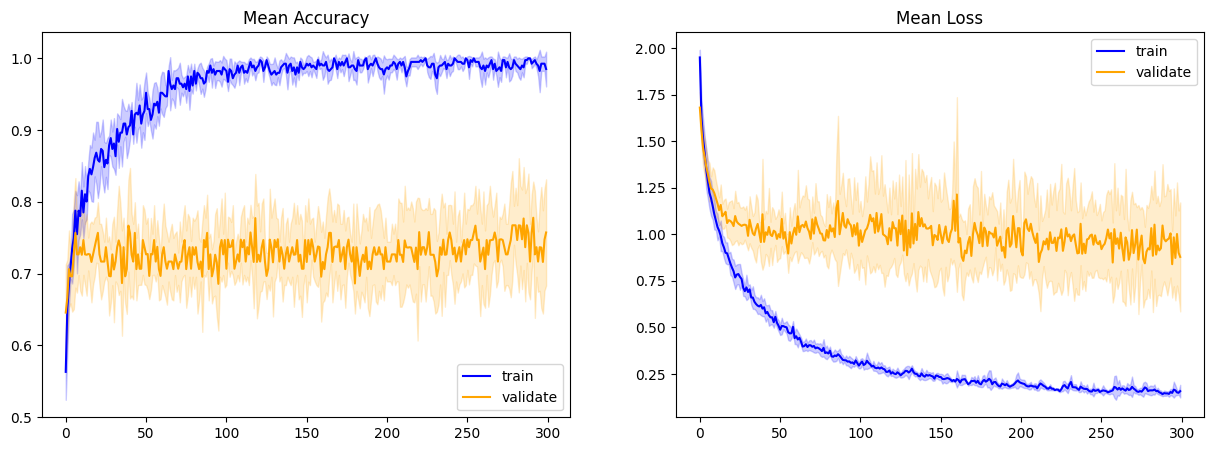

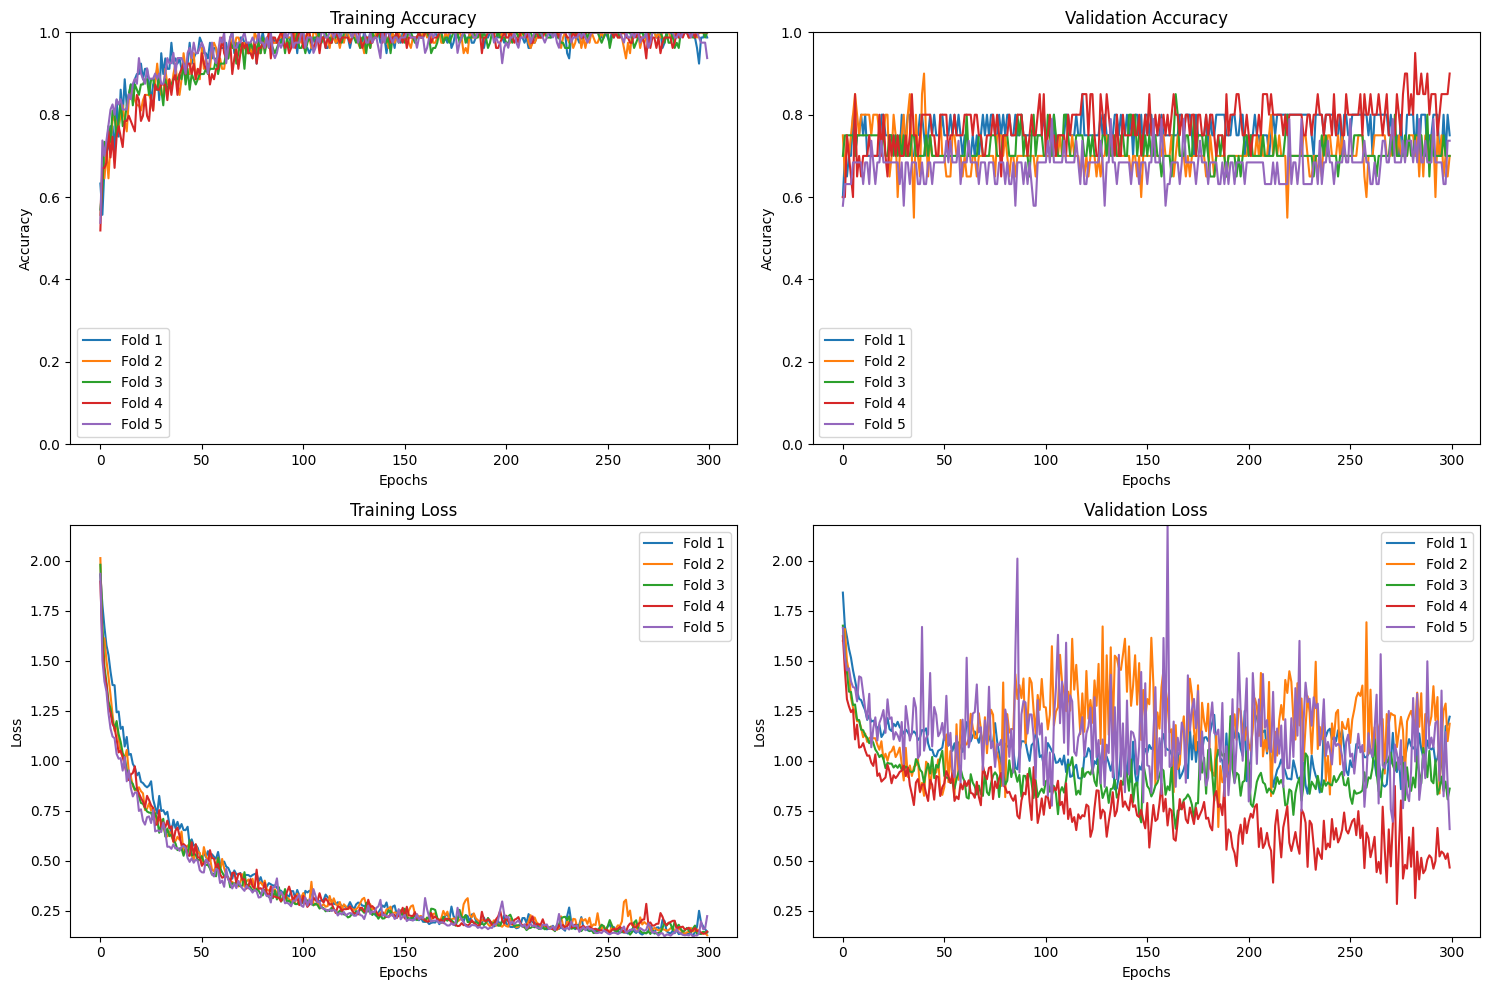

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
predicted classes:       [0 0 1 1 1 0 0 0 1 1 0 1 0 0 0 1 1 0 0]
true validation classes: [1 0 1 1 1 0 0 0 1 0 1 1 1 0 0 1 0 0 0]


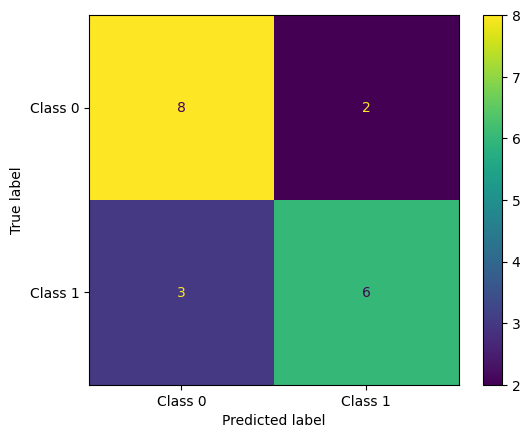

In [44]:
reset_weights(model2)
mean_acc_DNN_2_val, sd_acc_DNN_2_val = crossvalidate(embeddings_df, model2, column_names, 'pond',kf,300)

### Test

In [45]:
X_train = embeddings_df[column_names]
y_train = embeddings_df['pond']
y_train = keras.utils.to_categorical(y_train)
X_test = pd.DataFrame(embeddings_test, columns=column_names)
y_test = df_test['pond_2']
y_test = keras.utils.to_categorical(y_test)

Epoch 1/500
18/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9775 - loss: 0.2449  

33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9559 - loss: 0.2915 - val_accuracy: 0.7600 - val_loss: 0.8225
Epoch 2/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8430 - loss: 0.6103 - val_accuracy: 0.7600 - val_loss: 0.6388
Epoch 3/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9135 - loss: 0.3875 - val_accuracy: 0.6800 - val_loss: 0.7799
Epoch 4/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8695 - loss: 0.3748 - val_accuracy: 0.7200 - val_loss: 0.6422
Epoch 5/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9061 - loss: 0.3565 - val_accuracy: 0.7200 - val_loss: 0.7255
Epoch 6/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9091 - loss: 0.3147 - val_accuracy: 0.8000 - val_loss: 0.6586
Epoch 7/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9168 - loss: 0.3400 - val_accuracy: 0.8000 - val_loss: 0.6421
Epoch 8/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9904 - loss: 0.1901 - val_accuracy: 0.7600 - val_loss: 0.

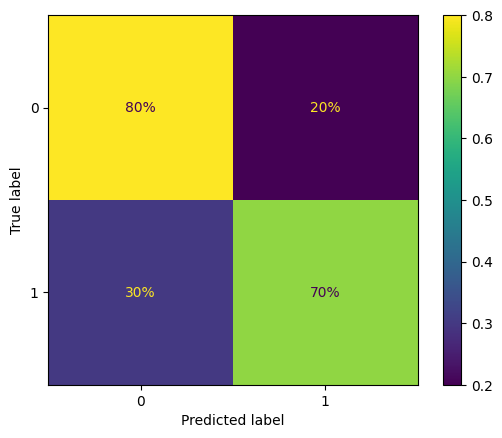

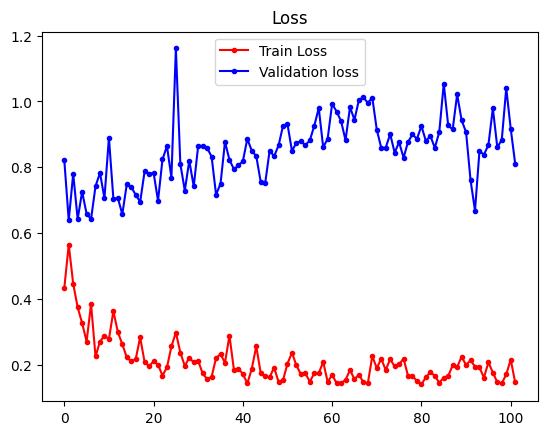

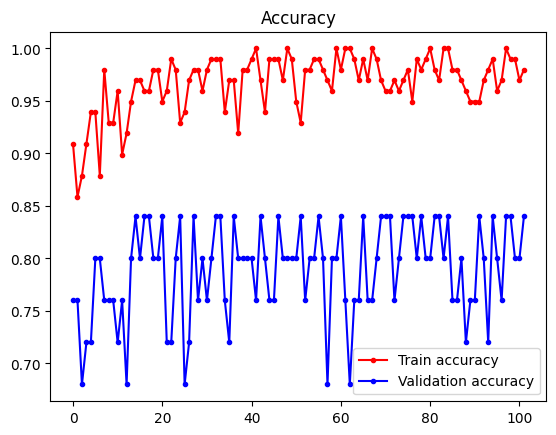

In [46]:
#  reset_weights(model4)
history2 = model2.fit(X_train, y_train, epochs = 500, verbose = 1, shuffle = True, 
                      batch_size = 3, validation_data = (X_test, y_test), 
                      callbacks = [EarlyStopping(monitor='val_loss', patience=100, restore_best_weights=True)])
acc_DNN_2_test = evaluate_model(model2, history2, X_test, y_test)

## Shallow model

In [47]:
model2_s = Sequential([
    Dense(19, input_shape=(encoding_dim,), activation='relu', kernel_regularizer=l2(0.01)),
    Dropout(rate=0.25),
    Dense(2, activation='softmax')
])
model2_s.summary()
model2_s.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])


C:\Users\marek\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\keras\src\layers\core\dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_30 (Dense)                │ (None, 19)             │           380 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 19)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_31 (Dense)                │ (None, 2)              │            40 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 420 (1.64 KB)

 Trainable params: 420 (1.64 KB)

 Non-trainable params: 0 (0.00 B)

### Crossvalidation


Number of classes: 2
training for 1 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 382ms/step - accuracy: 0.7000 - loss: 0.8100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step
predicted classes:       [0 0 1 0 1 0 0 1 0 0 0 1 1 1 1 0 1 0 1 1]
true validation classes: [0 0 0 1 1 0 0 0 0 0 0 1 1 1 0 1 1 0 0 1]
mean confidence score: 3996.6596, sd confidence score: 12926.7557
training for 2 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step - accuracy: 0.8000 - loss: 0.7079
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
predicted classes:       [0 1 0 1 1 0 1 1 0 0 0 0 0 1 1 1 0 0 1 0]
true validation classes: [0 0 0 1 1 0 0 1 0 0 0 0 1 1 0 1 0 0 1 0]
mean confidence score: 107.2746, sd confidence score: 174.7536
training for 3 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step - accuracy: 0.8000 - loss: 0.5656
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
predicted classes:       [0 0 0 1 0 0 0 0 0 1 0 0 1 0 1 0 1 0 1 0]
true validation classes: [0 0 1 1 0 1 0 0 0 1 0 0 1 1 1 0 0 0 1 0]
mean confidence score: 68009164820.0588, sd confid

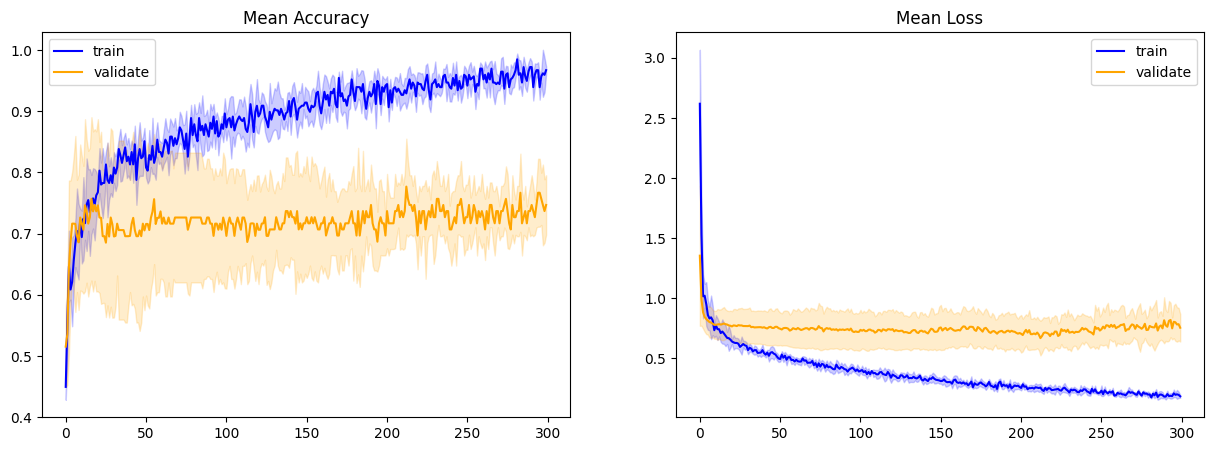

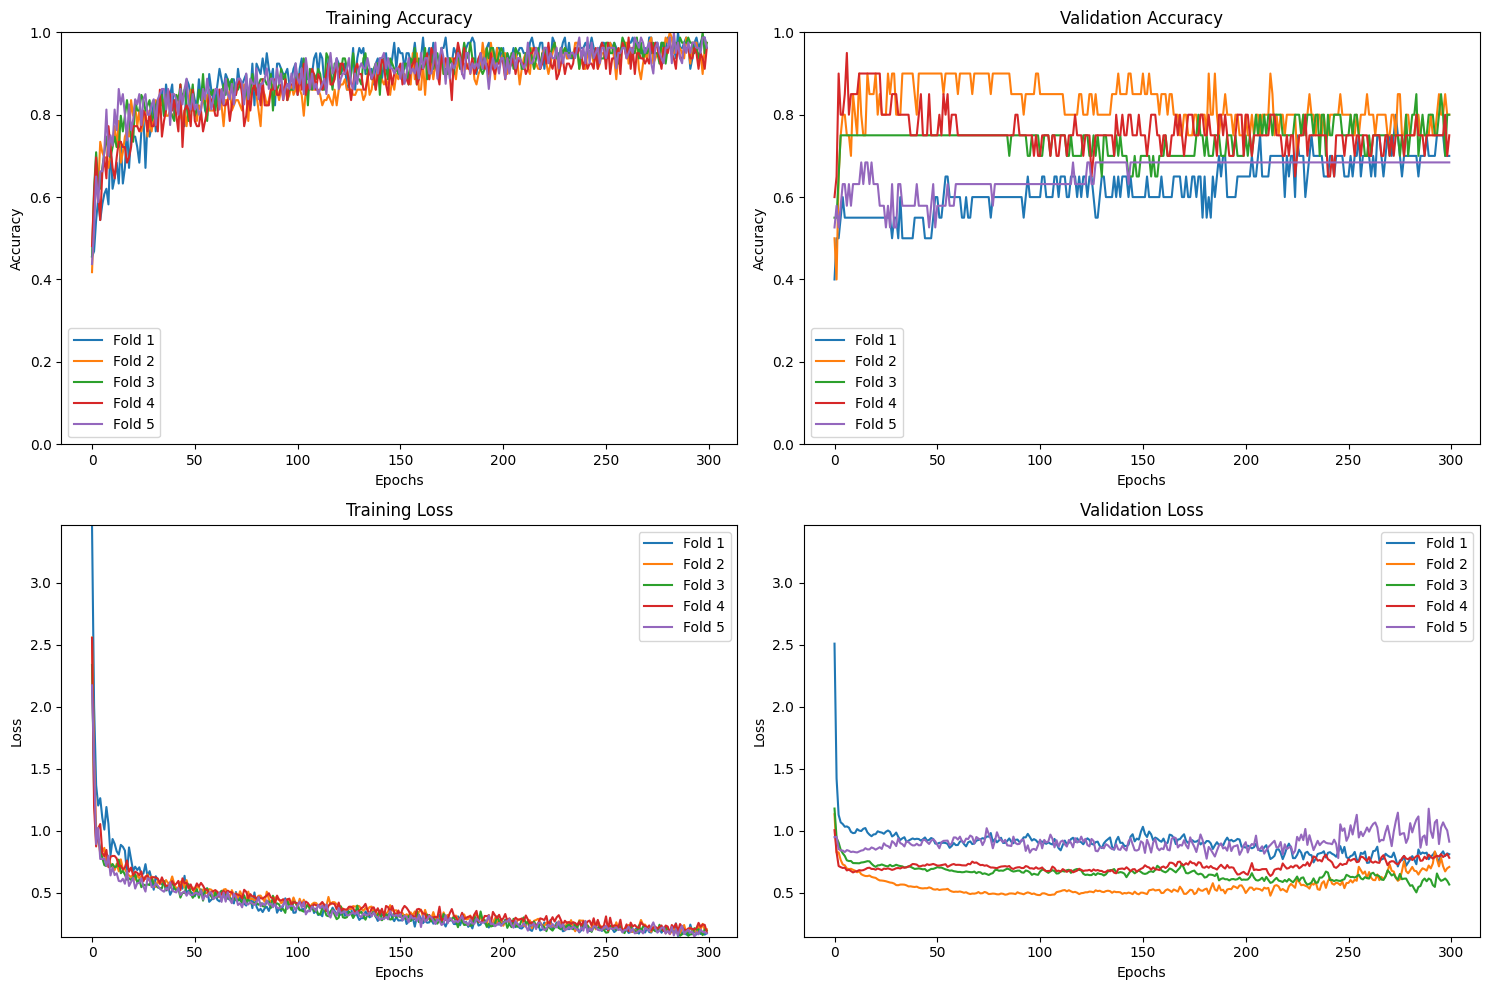

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
predicted classes:       [0 0 0 1 0 0 0 0 1 0 0 1 0 0 0 0 0 0 0]
true validation classes: [1 0 1 1 1 0 0 0 1 0 1 1 1 0 0 1 0 0 0]


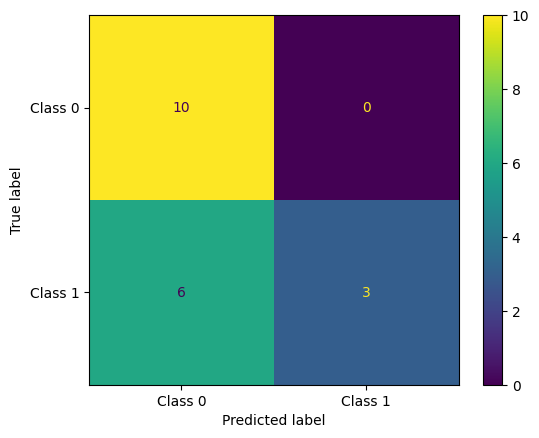

In [48]:
reset_weights(model2_s)
mean_acc_SNN_2_val, sd_acc_SNN_2_val = crossvalidate(embeddings_df, model2_s, column_names, 'pond',kf, 300,True)

### Test

In [49]:
reset_weights(model2_s)
history2_s=model2_s.fit(X_train, y_train, epochs = 500, verbose = 1, shuffle = True, 
                        batch_size = 3, validation_data = (X_test, y_test), 
                        callbacks = [EarlyStopping(monitor='val_loss', patience=100, restore_best_weights=True)])
acc_SNN_2_test =  evaluate_model(model2_s, history2_s, X_test, y_test)




Epoch 1/500


ValueError: Exception encountered when calling Sequential.call().

[1mCannot take the length of shape with unknown rank.[0m

Arguments received by Sequential.call():
  • inputs=tf.Tensor(shape=<unknown>, dtype=float32)
  • training=True
  • mask=None

## XGBoost

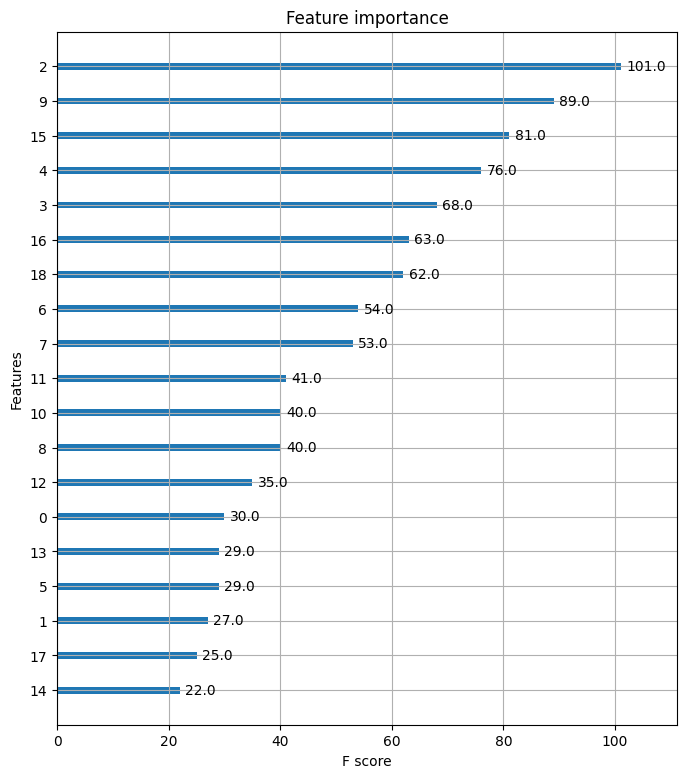

Accuracy0.8
true: [0 0 1 0 0 0 0 0 1 1 1 0 1 0 1 0 0 0 1 1 0 0 1 0 1]
predicted: [0. 1. 1. 0. 0. 1. 0. 0. 0. 1. 1. 1. 1. 0. 1. 0. 0. 0. 1. 1. 0. 0. 0. 0.
 1.]


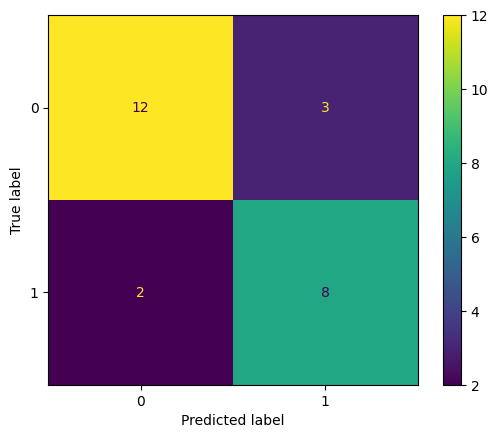

In [ ]:
target = "pond_2"
dtrain = xgb.DMatrix(X_train, label=df_train_val[target].values, feature_names=column_names)  
dtest = xgb.DMatrix(X_test, label=df_test[target].values, feature_names=column_names)
params = {
    'objective': 'multi:softmax',
    'num_class': 5,
    'max_depth': 3, # maximum deepth of the tree, used to controll complexity of the model
    'eta': 0.1,
    'seed': 111
}

x2 = xgb.train(params, dtrain, num_boost_round=100)

xgb_pred = x2.predict(dtest)
xgb_acc = accuracy_score(df_test[target].values, xgb_pred)
acc_XGB_2_test = xgb_acc
fig, ax = plt.subplots(figsize=(8, 9))
xgb.plot_importance(x2, ax=ax)
plt.show()

print(f"Accuracy{xgb_acc}")
print(f"true: {df_test[target].values}")
print(f"predicted: {xgb_pred}")

cm = confusion_matrix(df_test[target].values, xgb_pred)
ConfusionMatrixDisplay(cm).plot()

# END

In [ ]:
emb_name = 'AE'
model = ['DNN','DNN','DNN','SNN','SNN','SNN','XGB','XGB','XGB']
classes = [5,3,2,5,3,2,5,3,2]
mean_acc = [mean_acc_DNN_5_val, mean_acc_DNN_3_val, mean_acc_DNN_2_val, ]




In [ ]:
print("DNN")
print(f"Accuracy class 5: {round(mean_acc_DNN_5_val,2)}, sd: {round(sd_acc_DNN_5_val,2)}, test: {acc_DNN_5_test}")
print(f"Accuracy class 3: {round(mean_acc_DNN_3_val,2)}, sd: {round(sd_acc_DNN_3_val,2)}, test: {acc_DNN_3_test}")
print(f"Accuracy class 2: {round(mean_acc_DNN_2_val,2)}, sd: {round(sd_acc_DNN_2_val,2)}, test: {acc_DNN_2_test}")
print("SNN")
print(f"Accuracy class 5: {round(mean_acc_SNN_5_val,2)}, sd: {round(sd_acc_SNN_5_val,2)}, test: {acc_SNN_5_test}")
print(f"Accuracy class 3: {round(mean_acc_SNN_3_val,2)}, sd: {round(sd_acc_SNN_3_val,2)}, test: {acc_SNN_3_test}")
print(f"Accuracy class 2: {round(mean_acc_SNN_2_val,2)}, sd: {round(sd_acc_SNN_2_val,2)}, test: {acc_SNN_2_test}")
print("XGB")
print(f"Accuracy class 5: {acc_XGB_5_test}")
print(f"Accuracy class 3: {acc_XGB_3_test}")
print(f"Accuracy class 2: {acc_XGB_2_test}")


DNN
Accuracy class 5: 0.57, sd: 0.08, test: 0.7599999904632568
Accuracy class 3: 0.67, sd: 0.07, test: 0.8399999737739563
Accuracy class 2: 0.76, sd: 0.07, test: 0.8399999737739563
SNN
Accuracy class 5: 0.45, sd: 0.07, test: 0.5600000023841858
Accuracy class 3: 0.67, sd: 0.05, test: 0.7599999904632568
Accuracy class 2: 0.77, sd: 0.08, test: 0.8799999952316284
XGB
Accuracy class 5: 0.52
Accuracy class 3: 0.72
Accuracy class 2: 0.8


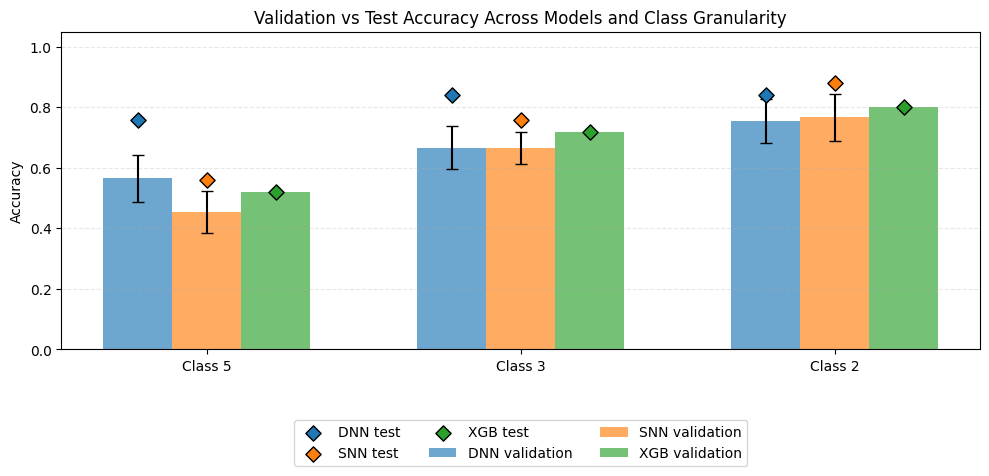

In [ ]:
accuracy_rows = [
    ("DNN", "Class 5", mean_acc_DNN_5_val, sd_acc_DNN_5_val, acc_DNN_5_test),
    ("DNN", "Class 3", mean_acc_DNN_3_val, sd_acc_DNN_3_val, acc_DNN_3_test),
    ("DNN", "Class 2", mean_acc_DNN_2_val, sd_acc_DNN_2_val, acc_DNN_2_test),
    ("SNN", "Class 5", mean_acc_SNN_5_val, sd_acc_SNN_5_val, acc_SNN_5_test),
    ("SNN", "Class 3", mean_acc_SNN_3_val, sd_acc_SNN_3_val, acc_SNN_3_test),
    ("SNN", "Class 2", mean_acc_SNN_2_val, sd_acc_SNN_2_val, acc_SNN_2_test),
    ("XGB", "Class 5", acc_XGB_5_test, 0.0, acc_XGB_5_test),
    ("XGB", "Class 3", acc_XGB_3_test, 0.0, acc_XGB_3_test),
    ("XGB", "Class 2", acc_XGB_2_test, 0.0, acc_XGB_2_test),
]

accuracy_df = pd.DataFrame(
    accuracy_rows,
    columns=["Model", "Class", "val_mean", "val_sd", "test_acc"],
)

class_labels = ["Class 5", "Class 3", "Class 2"]
model_order = ["DNN", "SNN", "XGB"]
x_positions = np.arange(len(class_labels))
bar_width = 0.22
palette = {"DNN": "#1f77b4", "SNN": "#ff7f0e", "XGB": "#2ca02c"}

fig, ax = plt.subplots(figsize=(10, 5))
for idx, model in enumerate(model_order):
    subset = accuracy_df[accuracy_df["Model"] == model].set_index("Class").loc[class_labels]
    offsets = x_positions + (idx - (len(model_order) - 1) / 2) * bar_width
    ax.bar(
        offsets,
        subset["val_mean"],
        bar_width,
        yerr=subset["val_sd"],
        capsize=4,
        alpha=0.65,
        color=palette[model],
        label=f"{model} validation",
    )
    ax.scatter(
        offsets,
        subset["test_acc"],
        color=palette[model],
        edgecolors="black",
        marker="D",
        s=60,
        zorder=3,
        label=f"{model} test",
    )

ax.set_xticks(x_positions)
ax.set_xticklabels(class_labels)
ax.set_ylabel("Accuracy")
ax.set_ylim(0, 1.05)
ax.set_title("Validation vs Test Accuracy Across Models and Class Granularity")
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.legend(ncol=3, bbox_to_anchor=(0.5, -0.2), loc="upper center")
plt.tight_layout()
plt.show()

In [ ]:
resultsdf = pd.DataFrame(accuracy_rows, columns=["Model", "Class", "val_mean", "val_sd", "test_acc"])
print(resultsdf)
resultsdf.to_csv("results\\Gut_3_Embedding_results.csv", index=False)


  Model    Class  val_mean    val_sd  test_acc
0   DNN  Class 5  0.566316  0.077877      0.76
1   DNN  Class 3  0.667368  0.072157      0.84
2   DNN  Class 2  0.756316  0.072559      0.84
3   SNN  Class 5  0.454211  0.068190      0.56
4   SNN  Class 3  0.666316  0.052931      0.76
5   SNN  Class 2  0.766842  0.077987      0.88
6   XGB  Class 5  0.520000  0.000000      0.52
7   XGB  Class 3  0.720000  0.000000      0.72
8   XGB  Class 2  0.800000  0.000000      0.80
